<a href="https://colab.research.google.com/github/DianaKlapneva/recsys_course_fork/blob/hw3/RECSYS_%D0%9B%D0%A03_%D0%9A%D0%BB%D0%B0%D0%BF%D0%BD%D0%B5%D0%B2%D0%B0_%D0%94%D0%B8%D0%B0%D0%BD%D0%B0_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание 3. Ранжирование (20p)

В ДЗ 2 мы строили retrieval-этап рекомендательной системы. Теперь добавим
второй этап — ranking, тем самым формируя полноценный рекомендательный пайплайн.

Итак, пусть каждый кандидатогенератор возвращает не более 100 товаров.
Кандидатогенераторов у нас несколько, и их необходимо объединить посредством ранкинга.
Финальная выдача будет состоять из 20 айтемов.

В качестве кандидатогенераторов возьмем TopPopular, ContentItemKNN и ALS из предыдущей работы,
а в качестве ранкера будет CatBoost. Попробуем две вариации - CatBoostClassifier и CatBoostRanker.
Качество итоговых рекомендаций будем оценивать с помощью `ExpNDCG`, `HitRate` и `MRR`.

В рамках работы необходимо:

1. собрать point-in-time датамарт `Raw → Aggs → Features` с историческими признаками пользователей и товаров;
2. получить кандидатов из нескольких retrieval-источников, объединить их, дедуплицировать, разметить и дополнить признаками;
3. обучить CatBoostClassifier и CatBoostRanker, подобрать гиперпараметры с помощью `optuna` и выбрать лучший вариант по качеству на `validation`;
4. оценить итоговую связку retrieval + ranking на `test`.

Реализации retrieval-моделей можно перенести из ДЗ 2 без изменений.

In [1]:
!pip install -q implicit polars sentence-transformers optuna catboost

In [2]:
!git clone https://github.com/sonya-leaf/recsys_course.git

fatal: destination path 'recsys_course' already exists and is not an empty directory.


In [3]:
%cd /content/recsys_course/homeworks
!ls
!python download_data.py

/content/recsys_course/homeworks
data  download_data.py	hw1  hw2  hw3  hw4  README.md
Already exists: /content/recsys_course/homeworks/data/raw/reviews_Beauty_5.json.gz
Already exists: /content/recsys_course/homeworks/data/raw/meta_Beauty.json.gz
Saved 198,502 interactions, 22,363 users and 12,101 items to /content/recsys_course/homeworks/data


In [4]:
%cd /content/recsys_course/homeworks/hw2

/content/recsys_course/homeworks/hw2


In [5]:
import sys
sys.path.insert(0, "/content/recsys_course/homeworks/hw2")

import importlib
import tests
importlib.reload(tests)

print(tests.__file__)
print([name for name in dir(tests) if name.startswith("check")])

/content/recsys_course/homeworks/hw2/tests.py
['check_als_retriever', 'check_base_recommender', 'check_bpr_retriever', 'check_causal_self_attention', 'check_cold_start_report', 'check_coverage_at_k', 'check_decay_popularity_retriever', 'check_ease_retriever', 'check_ease_weights', 'check_encode_titles', 'check_evaluate', 'check_events_by_month', 'check_feed_forward', 'check_hit_rate_at_k', 'check_item_popularity_curve', 'check_map_at_k', 'check_matrix_recommender', 'check_metric_data_helpers', 'check_mrr_at_k', 'check_ndcg_at_k', 'check_next_item_loss', 'check_next_item_transformer', 'check_random_retriever', 'check_rating_distribution', 'check_recall_at_k', 'check_sequence_data', 'check_temporal_ratio_split', 'check_text_itemknn', 'check_top_n_indices', 'check_top_popular_retriever', 'check_train_epoch', 'check_transformer_block', 'check_transformer_retriever', 'check_user_activity_distribution']


In [6]:
import hashlib
import math
import random
from abc import ABC, abstractmethod
from collections import Counter
from collections.abc import Callable, Iterable, Mapping, Sequence
from datetime import date, datetime, timedelta
from pathlib import Path
from typing import Any, Literal, Self

import implicit
import matplotlib.pyplot as plt
import numpy as np
import optuna
import polars as pl
import tests
from catboost import CatBoostClassifier, CatBoostRanker, Pool
from numpy.typing import NDArray
from optuna.samplers import TPESampler
from scipy import sparse
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42
RETRIEVAL_K = 100
EVAL_K = 20
DATA_DIR = Path("../data")
DATAMART_DIR = DATA_DIR / "ranking_datamart"

random.seed(SEED)
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

interactions = pl.read_parquet(DATA_DIR / "interactions.parquet")
items = pl.read_parquet(DATA_DIR / "items.parquet")
users = pl.read_parquet(DATA_DIR / "users.parquet")

interactions = interactions.with_columns(
    pl.col("user_id").cast(pl.Utf8),
    pl.col("item_id").cast(pl.Utf8),
    pl.col("rating").cast(pl.Float64),
    pl.col("timestamp").cast(pl.Datetime("us", "UTC")),
)

users = users.with_columns(pl.col("user_id").cast(pl.Utf8)).filter(
    pl.col("user_id").is_in(interactions["user_id"].unique().to_list())
)
items = items.with_columns(pl.col("item_id").cast(pl.Utf8)).filter(
    pl.col("item_id").is_in(interactions["item_id"].unique().to_list())
)

In [8]:
import os, pathlib
print("cwd:", os.getcwd())
print("файлы в cwd:", sorted(os.listdir(".")))
print("hw3/tests.py exists:", pathlib.Path("/content/recsys_course/homeworks/hw3/tests.py").exists())

cwd: /content/recsys_course/homeworks/hw2
файлы в cwd: ['README.md', '__pycache__', 'homework.ipynb', 'requirements.txt', 'tests.py']
hw3/tests.py exists: True


In [9]:
%cd /content/recsys_course/homeworks/hw3

/content/recsys_course/homeworks/hw3


In [10]:
import sys, importlib


sys.path = [p for p in sys.path if "hw2" not in p]


hw3 = "/content/recsys_course/homeworks/hw3"
if hw3 in sys.path:
    sys.path.remove(hw3)
sys.path.insert(0, hw3)

sys.modules.pop("tests", None)
import tests
importlib.reload(tests)

print("файл:", tests.__file__)
print("check_weekly_sessions:", hasattr(tests, "check_weekly_sessions"))
print("все check*:", [n for n in dir(tests) if n.startswith("check")])

файл: /content/recsys_course/homeworks/hw3/tests.py
check_weekly_sessions: True
все check*: ['check_aggs_layer', 'check_candidate_deduplication', 'check_candidate_labels', 'check_candidate_scoring', 'check_category_features', 'check_evaluate_ranking', 'check_exp_ndcg_at_k', 'check_feature_join', 'check_feature_storage', 'check_hit_rate_at_k', 'check_informative_candidate_groups', 'check_informative_ranking_groups', 'check_item_categories', 'check_lifetime_features', 'check_mrr_at_k', 'check_point_in_time_leakage', 'check_positive_labels', 'check_ranking_groups', 'check_raw_layer', 'check_rerank_candidates', 'check_rolling_features', 'check_temporal_week_split', 'check_weekly_counters', 'check_weekly_counters_reader', 'check_weekly_sessions']


## 1. Предобработка (1p)

Будем решать задачу рекомендаций с недельным горизонтом: на начало каждой недели для пользователя нужно сформировать список товаров, а события этой недели будут использоваться как ground truth. Поэтому объединим взаимодействия в сессии по паре `(user_id, week_start)`. В предыдущем ДЗ наблюдаемая оценка считалась фактом взаимодействия. Сохраним эту трактовку: само наличие оценки — наблюдаемое событие, а число от 1 до 5 отражает его силу.

Для пользователя $u$ и календарной недели, начинающейся в момент $t$, определим запрос ранжирования как

$$s=(u,t).$$

Здесь $t$ — понедельник, 00:00 UTC.

Нужно реализовать функцию `add_weekly_sessions`: нормализовать timestamp к началу недели и собрать `session_id` из даты начала недели и `user_id`.

In [11]:
def add_weekly_sessions(interactions: pl.DataFrame) -> pl.DataFrame:
    """Добавляет в данные колонки `week_start` и `session_id`."""
    return interactions.with_columns(
        pl.col("timestamp").dt.truncate("1w").alias("week_start"),
    ).with_columns(
        pl.concat_str(
            [
                pl.col("week_start").dt.strftime("%Y-%m-%d"),
                pl.col("user_id"),
            ],
            separator="_",
        ).alias("session_id"),
    )

tests.check_weekly_sessions(add_weekly_sessions)


All good! :)


Посмотрим на размер сессий.

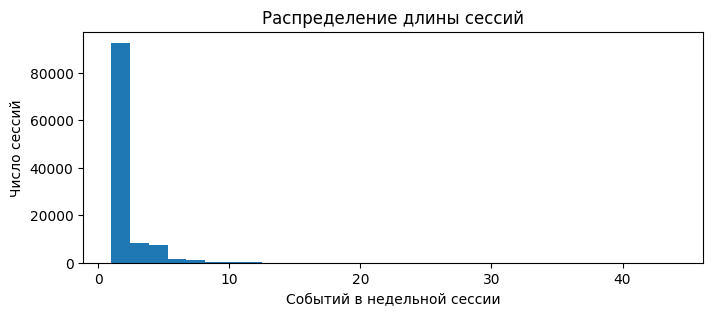

In [12]:
interactions = add_weekly_sessions(interactions)
session_sizes = interactions.group_by("session_id").agg(pl.len().alias("events"))

plt.figure(figsize=(8, 3))
plt.hist(session_sizes["events"].to_numpy(), bins=30)
plt.xlabel("Событий в недельной сессии")
plt.ylabel("Число сессий")
plt.title("Распределение длины сессий")
plt.show()

## 2. Глобальное временное разбиение (1p)

Случайное разбиение здесь использовать нельзя: оно позволило бы модели учиться на событиях, произошедших позже оцениваемой недели. Поэтому разделим данные по времени: на `train` обучим модели, по `validation` выберем гиперпараметры, а `test` оставим только для финальной оценки.

Границы задаются сразу для всех пользователей и проходят между неделями. Благодаря этому каждая недельная сессия целиком относится только к одной выборке.

Выберем две границы $T_{val}$ и $T_{test}$, приходящиеся на понедельник в 00:00 UTC:

$$Train=\{e:t_e<T_{val}\},$$
$$Validation=\{e:T_{val}\le t_e<T_{test}\},$$
$$Test=\{e:t_e\ge T_{test}\}.$$

Границы допустимы только между полными неделями. Доли `train_ratio`, `validation_ratio` и `test_ratio` относятся к числу событий, а не к числу недель. Из всех допустимых пар границ выберите ту, для которой накопленные доли событий ближе всего к заданным; при равенстве используйте более ранние границы. Необходимо реализовать функцию `temporal_week_split`, которая выберет глобальные недельные границы и вернёт три непересекающиеся части данных. Внутри периода нужно придерживаться исходного порядка событий.

In [13]:
def temporal_week_split(
    interactions: pl.DataFrame,
    train_ratio: float = 0.8,
    validation_ratio: float = 0.1,
    test_ratio: float = 0.1,
) -> tuple[pl.DataFrame, pl.DataFrame, pl.DataFrame]:
    """Разделяет данные на train, validation и test по границам недель."""
    ratios = (train_ratio, validation_ratio, test_ratio)
    if any(r <= 0 for r in ratios) or not np.isclose(sum(ratios), 1.0):
        raise ValueError("Все доли должны быть положительными и суммироваться в 1")

    with_week = interactions.with_columns(
        pl.col("timestamp").dt.truncate("1w").alias("week_start"),
    )

    weekly = (
        with_week.group_by("week_start")
        .len(name="n_events")
        .sort("week_start")
    )
    total = weekly["n_events"].sum()
    weekly = weekly.with_columns(
        (pl.col("n_events").cum_sum() / total).alias("cum_ratio"),
    )

    target_val = train_ratio
    target_test = train_ratio + validation_ratio
    weekly = weekly.with_columns(
        (pl.col("cum_ratio") - pl.col("n_events") / total).alias("cum_before"),
    )

    def _closest_week_start(df: pl.DataFrame, target: float) -> pl.Date:
        diff = (df["cum_before"] - target).abs()
        idx = int(np.argmin(diff.to_numpy()))
        return df["week_start"][idx]

    t_val = _closest_week_start(weekly, target_val)
    t_test = _closest_week_start(weekly, target_test)

    train = with_week.filter(pl.col("timestamp") < t_val)
    validation = with_week.filter(
        (pl.col("timestamp") >= t_val) & (pl.col("timestamp") < t_test)
    )
    test = with_week.filter(pl.col("timestamp") >= t_test)

    return train, validation, test


tests.check_temporal_week_split(add_weekly_sessions, temporal_week_split)

All good! :)


In [14]:
train_events, val_events, test_events = temporal_week_split(interactions)

t_val = val_events["week_start"].min()
t_test = test_events["week_start"].min()

split_stats = pl.DataFrame(
    {
        "split": ["train", "validation", "test"],
        "events": [len(train_events), len(val_events), len(test_events)],
        "sessions": [
            x["session_id"].n_unique() for x in (train_events, val_events, test_events)
        ],
        "users": [
            x["user_id"].n_unique() for x in (train_events, val_events, test_events)
        ],
        "items": [
            x["item_id"].n_unique() for x in (train_events, val_events, test_events)
        ],
    }
)

display(split_stats)
print("T_val:", t_val, "T_test:", t_test)

split,events,sessions,users,items
str,i64,i64,i64,i64
"""train""",159467,92063,20860,11785
"""validation""",18541,9636,6543,6423
"""test""",20494,10137,6273,6479


T_val: 2014-03-10 00:00:00+00:00 T_test: 2014-05-12 00:00:00+00:00


Зафиксируем главное правило для всей домашней работы. В начале недели $t$ известны только события с моментом времени **строго раньше** её начала:

$$H(t)=\{e:timestamp_e<t\}.$$

Это касается негативного сэмплирования, популярности товаров и всех признаков. Предположим, пользователь поставил оценку в среду. Эту оценку разрешено использовать как целевой ответ для текущей недели, но **нельзя** включать в фичи на её начало.

## 3. Базис (1p)

Обучающую таблицу удобно разделить на `basis` и признаки. `Basis` определяет состав строк и target: какая пара `(session_id, item_id)` присутствует в выборке и насколько товар релевантен. Признаки будут рассчитаны отдельно по прошлым событиям и присоединены к этим строкам позднее.

Иными словами, `basis` отвечает на вопрос «что ранжируем и с какой меткой», а features — «что было известно об этих объектах на момент формирования рекомендаций». Итоговый ranking dataset получается point-in-time объединением этих двух частей.

Сначала построим положительную часть `basis` — товары, с которыми пользователь впервые взаимодействовал в данной недельной сессии. После генерации кандидатов добавим к ней псевдонегативы, так как истинных негативов в данных нет.

Все оценки 1–5 — наблюдаемые положительные взаимодействия. Для classifier
используем `binary_target`, для ranker сохраняем исходную `relevance` 1–5.

Повторно рекомендовать уже оценённый товар не будем. Поэтому оставим только первую неделю
знакомства пользователя с товаром; несколько оценок внутри этой недели схлопываем через `max(rating)`.

Реализуйте функцию `build_positive_labels`, которая соберёт разметку положительных примеров. Выход — таблица с колонками `session_id`, `week_start`, `user_id`, `item_id`, `binary_target` (всегда `1`) и `relevance` (1–5), по одной строке на пару `(session_id, item_id)`.

In [15]:
def build_positive_labels(interactions: pl.DataFrame) -> pl.DataFrame:
    """Строит ground truth взаимодействия user–item."""
    with_week = interactions.with_columns(
        pl.col("timestamp").dt.truncate("1w").alias("week_start"),
    ).with_columns(
        pl.concat_str(
            [
                pl.col("week_start").dt.strftime("%Y-%m-%d"),
                pl.col("user_id"),
            ],
            separator="_",
        ).alias("session_id"),
    )


    first_week = with_week.group_by(["user_id", "item_id"]).agg(
        pl.col("week_start").min().alias("first_week_start"),
    )
    with_week = with_week.join(
        first_week, on=["user_id", "item_id"], how="left"
    ).filter(pl.col("week_start") == pl.col("first_week_start"))

    labels = with_week.group_by(
        ["session_id", "week_start", "user_id", "item_id"]
    ).agg(
        pl.col("rating").max().alias("relevance"),
    )

    labels = labels.with_columns(
        pl.lit(1).cast(pl.Int8).alias("binary_target"),
        pl.col("relevance").cast(pl.Int8),
    )

    labels = labels.select(
        ["session_id", "week_start", "user_id", "item_id", "binary_target", "relevance"]
    )

    return labels


tests.check_positive_labels(add_weekly_sessions, build_positive_labels)


All good! :)


Позднее для каждого candidate pool выполним left join с полным ground truth
соответствующей недели:

| Кандидат | `binary_target` | `relevance` |
|---|---:|---:|
| наблюдался в этой недельной сессии | 1 | 1–5 |
| не наблюдался | 0 | 0 |

Это всё ещё псевдонегативы: отсутствие оценки не доказывает неприязнь. Но такие
негативы согласованы с реальной задачей ранкера — переставить товары, уже
отобранные retrieval-моделями.

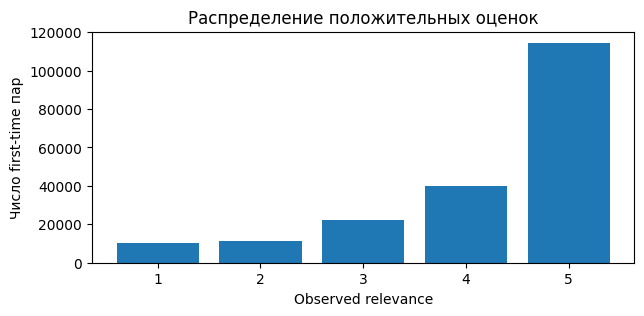

In [16]:
positives = build_positive_labels(interactions)
val_truth = positives.filter(
    (pl.col("week_start") >= t_val) & (pl.col("week_start") < t_test)
)
test_truth = positives.filter(pl.col("week_start") >= t_test)

label_dist = positives.group_by("relevance").agg(pl.len().alias("n")).sort("relevance")
plt.figure(figsize=(7, 3))
plt.bar(label_dist["relevance"].to_list(), label_dist["n"].to_list())
plt.xlabel("Observed relevance")
plt.ylabel("Число first-time пар")
plt.title("Распределение положительных оценок")
plt.show()

## 4. Кастомный датамарт (6p)

Датамарт — это подготовленный под конкретную задачу слой данных между исходными событиями и моделью. В отличие от общей таблицы взаимодействий, он хранит данные в форме, из которой можно воспроизводимо собирать обучающие выборки и признаки для нужного момента времени.

В этой работе датамарт позволит один раз сохранить сырые события и промежуточные агрегаты, а затем использовать их при построении признаков для разных недель. Благодаря этому нам не придётся заново обрабатывать всю историю для каждого эксперимента, а единое правило временного среза поможет не допустить утечку будущих событий в обучение.

Построим простой датамарт, состоящий из трёх слоёв:

1. **Raw** — исходные события по неделям.
2. **Aggs** — недельные счётчики по паре пользователь–товар.
3. **Features** — готовые исторические признаки на начало недели.

### 4.1. Raw: разложим события по неделям (1p)

Путь `raw/events/week=YYYY-MM-DD/events.parquet` соответствует событиям за интервал $[t,t+7\text{ дней})$. Напишите функцию `build_raw_layer`, сохраняющую каждое взаимодействие ровно в одну недельную партицию и не удаляющую повторные оценки.

In [17]:
def build_raw_layer(interactions: pl.DataFrame, datamart_dir: Path) -> None:
    """Разбивает события по неделям и записывает каждую часть в Raw layer."""
    with_week = interactions.with_columns(
        pl.col("timestamp").dt.truncate("1w").alias("week_start"),
    )

    weekly = with_week.partition_by("week_start", as_dict=True)
    for week_start, part in weekly.items():
        ws = week_start[0] if isinstance(week_start, tuple) else week_start
        week_str = ws.strftime("%Y-%m-%d") if hasattr(ws, "strftime") else str(ws)[:10]

        out_dir = Path(datamart_dir) / "raw" / "events" / f"week={week_str}"
        out_dir.mkdir(parents=True, exist_ok=True)
        part.write_parquet(out_dir / "events.parquet")


tests.check_raw_layer(add_weekly_sessions, build_raw_layer)


All good! :)


### 4.2. Aggs: посчитаем недельные счётчики (2p)

Следующий слой содержит по одной строке на `(week_start, user_id, item_id)` и позволяет собрать исторические статистики без повторного чтения сырых событий.

Для пары $(u,i)$ и недели $w$ нужны:

- `n_events` — число событий;
- `rating_sum` — сумма оценок, `rating_count` — число оценок;
- `n_high_ratings` — число оценок 4–5;
- `first_event_ts` и `last_event_ts` — границы наблюдаемой активности.

Недельные счётчики посчитайте в функции `calculate_weekly_counters`.

In [18]:
def calculate_weekly_counters(events: pl.DataFrame) -> pl.DataFrame:
    """Агрегирует события до одной строки на `(week, user, item)`."""
    if "week_start" not in events.columns:
        events = events.with_columns(
            pl.col("timestamp").dt.truncate("1w").alias("week_start"),
        )

    counters = events.group_by(["week_start", "user_id", "item_id"]).agg(
        pl.len().alias("n_events"),
        pl.col("rating").sum().alias("rating_sum"),
        pl.col("rating").count().alias("rating_count"),
        (pl.col("rating") >= 4).sum().alias("n_high_ratings"),
        pl.col("timestamp").min().alias("first_event_ts"),
        pl.col("timestamp").max().alias("last_event_ts"),
    )

    return counters


tests.check_weekly_counters(add_weekly_sessions, calculate_weekly_counters)


All good! :)


Далее необходимо реализовать `build_aggs_layer`: функция читает недельные raw-партиции, вызывает расчёт счётчиков и сохраняет `aggs/user_item/week=.../counters.parquet`.

In [19]:
def build_aggs_layer(datamart_dir: Path) -> None:
    """Читает недельные Raw-партиции и записывает агрегаты user–item."""
    raw_root = Path(datamart_dir) / "raw" / "events"
    if not raw_root.exists():
        raise FileNotFoundError(f"Raw layer не найден: {raw_root}")
    week_dirs = sorted(p for p in raw_root.iterdir() if p.is_dir() and p.name.startswith("week="))

    for week_dir in week_dirs:
        events_path = week_dir / "events.parquet"
        if not events_path.exists():
            continue

        events = pl.read_parquet(events_path)
        counters = calculate_weekly_counters(events)
        out_dir = Path(datamart_dir) / "aggs" / "user_item" / week_dir.name
        out_dir.mkdir(parents=True, exist_ok=True)
        counters.write_parquet(out_dir / "counters.parquet")


tests.check_aggs_layer(add_weekly_sessions, build_raw_layer, build_aggs_layer)


All good! :)


Теперь реализуйте `read_weekly_counters(datamart_dir, week_start, lookback_weeks=None)`: функция читает только партиции из окна $[week\_start - lookback\_weeks, week\_start)$, а при `lookback_weeks=None` — всю историю строго до `week_start`. При `lookback_weeks <= 0` функция выбрасывает `ValueError`, а строки с `week_start >= week_start` в результат не попадают. Вся сборка признаков должна опираться на Aggs, а не заново сканировать Raw.

In [20]:
from datetime import date, datetime, timedelta, timezone

In [21]:
def read_weekly_counters(
    datamart_dir: Path,
    week_start: datetime,
    lookback_weeks: int | None = None,
) -> pl.DataFrame:
    """Читает только партиции Aggs из окна `[week_start - lookback, week_start)`."""
    if lookback_weeks is not None and lookback_weeks <= 0:
        raise ValueError("lookback_weeks должен быть положительным")

    paths = sorted(
        (datamart_dir / "aggs" / "user_item").glob("week=*/counters.parquet")
    )
    if not paths:
        raise FileNotFoundError("Сначала постройте aggs layer")


    ws = week_start
    if isinstance(ws, datetime):
        if ws.tzinfo is None:
            ws = ws.replace(tzinfo=timezone.utc)
        ws = ws.astimezone(timezone.utc)
    ws_pl = pl.lit(ws).cast(pl.Datetime("us", "UTC"))

    if lookback_weeks is None:
        lower = None
    else:
        lower_dt = ws - timedelta(weeks=lookback_weeks)
        lower = pl.lit(lower_dt).cast(pl.Datetime("us", "UTC"))


    selected = []
    for p in paths:
        week_str = p.parent.name.removeprefix("week=")
        try:
            part_week = datetime.strptime(week_str, "%Y-%m-%d").replace(tzinfo=timezone.utc)
        except ValueError:
            continue
        if part_week >= ws:
            continue
        if lower is not None and part_week < lower_dt:
            continue
        selected.append(p)

    if not selected:
        #пустой результат с правильной схемой
        return pl.DataFrame(
            schema={
                "week_start": pl.Datetime("us", "UTC"),
                "user_id": pl.Utf8,
                "item_id": pl.Utf8,
                "n_events": pl.UInt32,
                "rating_sum": pl.Float64,
                "rating_count": pl.UInt32,
                "n_high_ratings": pl.UInt32,
                "first_event_ts": pl.Datetime("us", "UTC"),
                "last_event_ts": pl.Datetime("us", "UTC"),
            }
        )


    df = pl.concat([pl.read_parquet(p) for p in selected], how="vertical_relaxed")

    #убираем странности типа week_start >= week_start и < lower
    df = df.filter(pl.col("week_start") < ws_pl)
    if lower is not None:
        df = df.filter(pl.col("week_start") >= lower)

    return df


tests.check_weekly_counters_reader(
    add_weekly_sessions, build_raw_layer, build_aggs_layer, read_weekly_counters
)

All good! :)


### 4.3. Features (3p)

Мы хотим различать общую популярность товара и недавний интерес к нему. Поэтому для расчета признаков используем два временных окна на начало недели $t$:

$$W_{lifetime}(t)=(-\infty,t),$$
$$W_{4w}(t)=[t-28\text{ дней},t).$$

Для каждого временного среза будем получать признаки пользователя, товара, общие статистики и при доступных категориях признаки `user × category`.

Начнем с категорий. В метаданных Amazon категория может отсутствовать, быть строкой или списком категорий. Зафиксируем одну детерминированную категорию товара, если она присутствует, и сохраним словарь категорий отдельно. Логика следующая:

- Источник — колонка `category`, если она есть, иначе `categories`. Если обе колонки отсутствуют, функция возвращает `None` и не создаёт файл. Значение приводим к списку строк: `null` — пустой список, строка — список из одного элемента. Каждую метку очищаем от пробелов по краям, пустые строки и повторы внутри товара отбрасываем.
- Частота метки — число товаров каталога, у которых она есть.
- Выбор: самая редкая метка товара, при равенстве — лексикографически меньшая. Порядок строк в `items` на результат не влияет.
- Товар без меток получает `"unknown"`.
- Выход — таблица `item_id`/`category` (обе `String`), по строке на каждый товар, сохранённая в `common/item_categories.parquet` внутри `datamart_dir`.

Эту логику реализуйте в функции `prepare_item_categories(items, datamart_dir)`.

In [22]:
def prepare_item_categories(
    items: pl.DataFrame, datamart_dir: Path
) -> pl.DataFrame | None:
    """Строит таблицу соответствий между товарами и категориями."""
    source_column = next(
        (column for column in ("category", "categories") if column in items.columns),
        None,
    )
    if source_column is None:
        return None

    def _to_list_expr(col: str) -> pl.Expr:
        dtype = items.schema[col]
        if dtype == pl.Utf8:
            return pl.col(col).map_elements(
                lambda v: [] if v is None else [v], return_dtype=pl.List(pl.Utf8)
            )

        return pl.col(col).map_elements(
            lambda v: [] if v is None else [str(x) for x in v if x is not None],
            return_dtype=pl.List(pl.Utf8),
        )

    long_df = (
        items.select(
            pl.col("item_id").cast(pl.Utf8).alias("item_id"),
            _to_list_expr(source_column).alias("labels"),
        )

        .with_columns(
            pl.col("labels").list.eval(
                pl.element().str.strip_chars()
            ).list.eval(
                pl.element().filter(pl.element() != "")
            )
        )

        .with_columns(
            pl.col("labels").list.unique(maintain_order=True)
        )
        #explode в длинный формат
        .explode("labels")
        .rename({"labels": "category"})
        .drop_nulls("category")
    )

    #частота метки это число товаров каталога у которых она есть
    freq = (
        long_df.group_by("category")
        .agg(pl.col("item_id").n_unique().alias("freq"))
    )

    #ищем самую редкую метку
    chosen_known = (
        long_df.join(freq, on="category", how="left")
        .sort(["item_id", "freq", "category"])
        .group_by("item_id")
        .agg(pl.col("category").first().alias("category"))
    )

    #mбез метки значит неизвестно
    all_items = items.select(pl.col("item_id").cast(pl.Utf8).alias("item_id")).unique()
    result = (
        all_items.join(chosen_known, on="item_id", how="left")
        .with_columns(pl.col("category").fill_null("unknown"))
        .select(["item_id", "category"])
    )

    out_dir = Path(datamart_dir) / "common"
    out_dir.mkdir(parents=True, exist_ok=True)
    result.write_parquet(out_dir / "item_categories.parquet")

    return result


tests.check_item_categories(prepare_item_categories)

TypeError: unexpected value while building Series of type List(String)

Hint: Try setting `strict=False` to allow passing data with mixed types.

вроде тут проблема с самим тестом?

Обозначим через $N_u(t)$ число исторических оценок пользователя, через $S_u(t)$ их сумму, а через $H_u(t)$ число оценок 4–5. Тогда

$$user\_mean\_rating_u(t)=\frac{S_u(t)}{N_u(t)},\qquad user\_high\_rating\_share_u(t)=\frac{H_u(t)}{N_u(t)}.$$

По товарам считаем число событий, число уникальных пользователей, среднюю оценку и недавнюю популярность. Чтобы не доверять слишком сильно среднему рейтингу товара с одной оценкой, используем байесовское сглаживание:

$$BayesRating_i(t)=\frac{S_i(t)+m\bar r(t)}{N_i(t)+m},\qquad m=20.$$

Здесь $\bar r(t)$ — глобальная историческая средняя оценка, $S_i(t)$ — сумма оценок товара, $N_i(t)$ — их количество. При маленьком $N_i$ оценка ближе к глобальной средней.

Ниже — полный состав признаков одного snapshot. Везде $w<t$ означает завершённые недели, а окно давности — $[t-4\text{ недели},t)$.

| Признак | Что означает | Как считать |
|---|---|---|
| `user_events_total` | вся история пользователя | $\sum_{w<t} n\_events$ |
| `user_items_unique` | сколько разных товаров оценил пользователь | число уникальных `item_id`, а не сумма недельных `n_unique` |
| `user_mean_rating` | средняя оценка пользователя | $S_u(t)/N_u(t)$ |
| `user_high_rating_share` | доля оценок 4–5 | $H_u(t)/N_u(t)$ |
| `user_events_4w` | недавняя активность | $\sum_{w\in[t-4w,\,t)} n\_events$ |
| `user_days_since_last_event` | дней с последнего события | $(t-\max last\_event\_ts)/86400$ |
| `item_events_total` | вся история товара | $\sum_{w<t} n\_events$ |
| `item_users_unique` | сколько разных пользователей у товара | число уникальных `user_id`, а не сумма недельных `n_unique` |
| `item_mean_rating` | средняя оценка товара | $S_i(t)/N_i(t)$ |
| `item_bayesian_mean_rating` | сглаженная средняя оценка | $(S_i+m\bar r)/(N_i+m)$, $m=20$ |
| `item_events_4w` | недавняя популярность | $\sum_{w\in[t-4w,\,t)} n\_events$ |
| `item_age_weeks` | возраст товара в неделях | $(t-\min first\_event\_ts)/7$ дней |
| `global_events_total` | размер глобальной истории | $\sum_{w<t} rating\_count$ |
| `global_mean_rating` | глобальная средняя оценка | $\sum rating\_sum / \sum rating\_count$ |
| `user_category_events_total` | история пользователя внутри категории | $\sum_{w<t} n\_events$ по товарам категории |
| `user_category_events_4w` | недавняя активность в категории | то же по окну $[t-4w,\,t)$ |
| `user_category_mean_rating` | средняя оценка пользователя в категории | $S_{u,c}/N_{u,c}$ |
| `category_events_total` | популярность категории | $\sum_{w<t} n\_events$ по категории |
| `category_events_4w` | недавняя популярность категории | то же по окну $[t-4w,\,t)$ |

Кросс-признаки (`user_item_rating_diff`, `item_recent_popularity_ratio`, `item_popularity_share`, `user_category_share`, `user_category_preference_lift`) считаются уже после присоединения snapshot к парам `session–item` в §5.

Соберём snapshot признаков в функции `calculate_feature_snapshot(datamart_dir, week_start, lookback_weeks=4)`: прочитайте нужные срезы Aggs через `read_weekly_counters` — всю историю строго до $t$ для lifetime-агрегатов и последние `lookback_weeks` недель для rolling, — затем посчитайте все признаки из таблицы выше. Функция возвращает словарь таблиц: обязательные ключи `"user"`, `"item"`, `"global"`, а при наличии категорий — ещё `"user_category"` и `"category"`. Названия колонок внутри таблиц должны совпадать с таблицей выше. При `lookback_weeks <= 0` — `ValueError`. Категорийный словарь функция должна читать сама из `common/item_categories.parquet`, если он существует.

In [24]:
def calculate_feature_snapshot(
    datamart_dir: Path,
    week_start: datetime,
    lookback_weeks: int = 4,
) -> dict[str, pl.DataFrame]:
    """Строит point-in-time таблицы признаков на начало недели."""
    if lookback_weeks <= 0:
        raise ValueError("lookback_weeks должен быть положительным")



    datamart_dir = Path(datamart_dir)
    t = week_start

    lifetime = read_weekly_counters(datamart_dir, t, lookback_weeks=None)
    rolling = read_weekly_counters(datamart_dir, t, lookback_weeks=lookback_weeks)

    if lifetime.height == 0:
        empty_user = pl.DataFrame(schema={
            "user_id": pl.Utf8,
            "user_events_total": pl.UInt32,
            "user_items_unique": pl.UInt32,
            "user_mean_rating": pl.Float64,
            "user_high_rating_share": pl.Float64,
            "user_events_4w": pl.UInt32,
            "user_days_since_last_event": pl.Float64,
        })
        empty_item = pl.DataFrame(schema={
            "item_id": pl.Utf8,
            "item_events_total": pl.UInt32,
            "item_users_unique": pl.UInt32,
            "item_mean_rating": pl.Float64,
            "item_bayesian_mean_rating": pl.Float64,
            "item_events_4w": pl.UInt32,
            "item_age_weeks": pl.Float64,
        })
        empty_global = pl.DataFrame(schema={
            "global_events_total": pl.UInt32,
            "global_mean_rating": pl.Float64,
        })
        out = {"user": empty_user, "item": empty_item, "global": empty_global}
        return out


    g_events_total = lifetime["rating_count"].sum()
    g_rating_sum = lifetime["rating_sum"].sum()
    g_mean = (g_rating_sum / g_events_total) if g_events_total > 0 else 0.0

    global_df = pl.DataFrame({
        "global_events_total": [int(g_events_total)],
        "global_mean_rating": [float(g_mean)],
    }, schema={
        "global_events_total": pl.UInt32,
        "global_mean_rating": pl.Float64,
    })


    user_life = lifetime.group_by("user_id").agg(
        pl.col("n_events").sum().alias("user_events_total"),
        pl.col("rating_count").sum().alias("_u_rating_count"),
        pl.col("rating_sum").sum().alias("_u_rating_sum"),
        pl.col("n_high_ratings").sum().alias("_u_high"),
        pl.col("last_event_ts").max().alias("_u_last_ts"),
        pl.col("item_id").n_unique().alias("user_items_unique"),
    ).with_columns(
        (pl.col("_u_rating_sum") / pl.col("_u_rating_count")).alias("user_mean_rating"),
        (pl.col("_u_high") / pl.col("_u_rating_count")).alias("user_high_rating_share"),
        ((pl.lit(t).cast(pl.Datetime("us", "UTC")) - pl.col("_u_last_ts"))
         .dt.total_seconds() / 86400.0).alias("user_days_since_last_event"),
    ).drop(["_u_rating_count", "_u_rating_sum", "_u_high", "_u_last_ts"])


    user_roll = rolling.group_by("user_id").agg(
        pl.col("n_events").sum().alias("user_events_4w"),
    )
    user_df = user_life.join(user_roll, on="user_id", how="left").with_columns(
        pl.col("user_events_4w").fill_null(0).cast(pl.UInt32),
    ).select([
        "user_id", "user_events_total", "user_items_unique",
        "user_mean_rating", "user_high_rating_share",
        "user_events_4w", "user_days_since_last_event",
    ])


    item_life = lifetime.group_by("item_id").agg(
        pl.col("n_events").sum().alias("item_events_total"),
        pl.col("rating_count").sum().alias("_i_rating_count"),
        pl.col("rating_sum").sum().alias("_i_rating_sum"),
        pl.col("user_id").n_unique().alias("item_users_unique"),
        pl.col("first_event_ts").min().alias("_i_first_ts"),
    ).with_columns(
        (pl.col("_i_rating_sum") / pl.col("_i_rating_count")).alias("item_mean_rating"),
        (
            (pl.col("_i_rating_sum") + 20.0 * g_mean)
            / (pl.col("_i_rating_count") + 20.0)
        ).alias("item_bayesian_mean_rating"),
        ((pl.lit(t).cast(pl.Datetime("us", "UTC")) - pl.col("_i_first_ts"))
         .dt.total_days() / 7.0).alias("item_age_weeks"),
    ).drop(["_i_rating_count", "_i_rating_sum", "_i_first_ts"])

    item_roll = rolling.group_by("item_id").agg(
        pl.col("n_events").sum().alias("item_events_4w"),
    )
    item_df = item_life.join(item_roll, on="item_id", how="left").with_columns(
        pl.col("item_events_4w").fill_null(0).cast(pl.UInt32),
    ).select([
        "item_id", "item_events_total", "item_users_unique",
        "item_mean_rating", "item_bayesian_mean_rating",
        "item_events_4w", "item_age_weeks",
    ])

    out = {"user": user_df, "item": item_df, "global": global_df}


    cat_path = datamart_dir / "common" / "item_categories.parquet"
    if cat_path.exists():
        item_cats = pl.read_parquet(cat_path)


        life_cat = lifetime.join(item_cats, on="item_id", how="inner")

        user_cat_life = life_cat.group_by(["user_id", "category"]).agg(
            pl.col("n_events").sum().alias("user_category_events_total"),
            pl.col("rating_count").sum().alias("_uc_rating_count"),
            pl.col("rating_sum").sum().alias("_uc_rating_sum"),
        ).with_columns(
            (pl.col("_uc_rating_sum") / pl.col("_uc_rating_count"))
            .alias("user_category_mean_rating"),
        ).drop(["_uc_rating_count", "_uc_rating_sum"])

        roll_cat = rolling.join(item_cats, on="item_id", how="inner")
        user_cat_roll = roll_cat.group_by(["user_id", "category"]).agg(
            pl.col("n_events").sum().alias("user_category_events_4w"),
        )
        user_cat_df = user_cat_life.join(
            user_cat_roll, on=["user_id", "category"], how="left"
        ).with_columns(
            pl.col("user_category_events_4w").fill_null(0).cast(pl.UInt32),
        ).select([
            "user_id", "category",
            "user_category_events_total", "user_category_events_4w",
            "user_category_mean_rating",
        ])

        cat_life = life_cat.group_by("category").agg(
            pl.col("n_events").sum().alias("category_events_total"),
        )
        cat_roll = roll_cat.group_by("category").agg(
            pl.col("n_events").sum().alias("category_events_4w"),
        )
        cat_df = cat_life.join(cat_roll, on="category", how="left").with_columns(
            pl.col("category_events_4w").fill_null(0).cast(pl.UInt32),
        ).select(["category", "category_events_total", "category_events_4w"])

        out["user_category"] = user_cat_df
        out["category"] = cat_df

    return out


tests.check_lifetime_features(
    add_weekly_sessions, build_raw_layer, build_aggs_layer, calculate_feature_snapshot
)
tests.check_rolling_features(
    add_weekly_sessions, build_raw_layer, build_aggs_layer, calculate_feature_snapshot
)
tests.check_point_in_time_leakage(
    add_weekly_sessions, build_raw_layer, build_aggs_layer, calculate_feature_snapshot
)
tests.check_category_features(
    add_weekly_sessions, build_raw_layer, build_aggs_layer, calculate_feature_snapshot
)

All good! :)
All good! :)
All good! :)
All good! :)


Таблица, сохранённая под именем `features/user/week=t.parquet`, означает **признаки, доступные на начало недели** $t$. Это важное соглашение: при сборке обучающих примеров мы не будем дополнительно сдвигать файл на неделю назад.

Подготовку snapshot вынесем в `build_features_layer(datamart_dir, weeks)`: для каждой запрошенной недели постройте snapshot через `calculate_feature_snapshot` и запишите его таблицы в `features/<entity>/week=t.parquet`. Функция опирается на уже сохранённый слой Aggs.

In [25]:
def build_features_layer(
    datamart_dir: Path, weeks: Sequence[datetime]
) -> None:
    """Строит и сохраняет point-in-time snapshots для заданных недель."""
    datamart_dir = Path(datamart_dir)

    for week_start in weeks:
        ws = week_start
        if isinstance(ws, datetime):
            if ws.tzinfo is None:
                ws = ws.replace(tzinfo=timezone.utc)
            ws = ws.astimezone(timezone.utc)
        week_str = ws.strftime("%Y-%m-%d")

        snapshot = calculate_feature_snapshot(datamart_dir, ws, lookback_weeks=4)


        for entity, table in snapshot.items():
            out_dir = datamart_dir / "features" / entity
            out_dir.mkdir(parents=True, exist_ok=True)
            table.write_parquet(out_dir / f"week={week_str}.parquet")


tests.check_feature_storage(
    add_weekly_sessions,
    build_raw_layer,
    build_aggs_layer,
    build_features_layer,
    calculate_feature_snapshot,
)


All good! :)


Применим наши функции ко всем взаимодействиям. Исходные события распределятся по Raw, недельные счётчики — по Aggs, а для каждой недели появится набор исторических файлов в Features. В оценочных неделях мы также строим snapshot на их начало.

In [26]:
build_raw_layer(interactions, DATAMART_DIR)
build_aggs_layer(DATAMART_DIR)
prepare_item_categories(items, DATAMART_DIR)

all_weeks = interactions["week_start"].unique().sort().to_list()
build_features_layer(DATAMART_DIR, all_weeks)

print("Недельных snapshots:", len(all_weeks))
print("Первый snapshot:", all_weeks[0])

first_raw_path = sorted(
    (DATAMART_DIR / "raw" / "events").glob("week=*/events.parquet")
)[0]
print("Пример raw-партиции:", first_raw_path, pl.read_parquet(first_raw_path).shape)

for entity in ("user", "item", "global"):
    print(
        entity,
        pl.read_parquet(
            DATAMART_DIR
            / "features"
            / entity
            / f"week={all_weeks[-1].date().isoformat()}.parquet"
        ).shape,
    )

Недельных snapshots: 529
Первый snapshot: 2002-06-10 00:00:00+00:00
Пример raw-партиции: ../data/ranking_datamart/raw/events/week=2002-06-10/events.parquet (3, 6)
user (22360, 7)
item (12101, 7)
global (1, 2)


## 5. Обогащение признаками (1p)

В этом разделе реализуем и проверим функцию, которая присоединяет к парам `session–item` рассчитанные ранее признаки. К полным выборкам train, validation и test применим её позже, после формирования retrieval candidate pools.

Обогащение выполняется как point-in-time join: для строки недели $t$ читается snapshot недели $t$, а ключами сущностей служат `user_id`, `item_id` и при необходимости категория товара. Состав входной таблицы при этом не меняется: строки нельзя терять или размножать, а target нельзя использовать при расчёте признаков.

Кросс-признаки вычисляются уже после объединения:

| Признак | Что означает | Как считать |
|---|---|---|
| `user_item_rating_diff` | разлад вкуса пользователя и оценки товара | $user\_mean\_rating_u(t)-item\_mean\_rating_i(t)$ |
| `item_recent_popularity_ratio` | насколько товар популярен сейчас против всей истории | $item\_events\_4w_i(t)/\max(item\_events\_total_i(t),1)$ |
| `item_popularity_share` | доля товара в глобальной истории | $item\_events\_total_i(t)/\max(global\_events\_total(t),1)$ |
| `user_category_share` | какая доля активности пользователя приходится на категорию товара | $user\_category\_events\_total_{u,c}(t)/\max(user\_events\_total_u(t),1)$ |
| `user_category_preference_lift` | во сколько раз интерес к категории выше её доли в истории | $user\_category\_share_{u,c}/\max(category\_events\_total_c(t)/\max(global\_events\_total(t),1),10^{-9})$ |

Для не встречавшихся в истории сущностей нужны согласованные значения по умолчанию: средние и счётчики — 0, `user_days_since_last_event` — большое число, заметно больше любого реального срока (например, 36500).

Для сборки итоговой таблицы понадобится `join_feature_snapshot`: присоедините по нужной неделе user-, item-, global- и при наличии категориальные признаки, затем вычислите кросс-признаки. Не размножайте строки и не используйте текущий рейтинг как входной признак.

In [27]:
def join_feature_snapshot(pairs: pl.DataFrame, datamart_dir: Path) -> pl.DataFrame:
    """Добавляет к парам session–item признаки на начало их недели."""
    if pairs.is_empty():
        return pairs

    datamart_dir = Path(datamart_dir)

    #если pairs пришли из build_positive_labels то она уже есть
    if "week_start" not in pairs.columns:
        pairs = pairs.with_columns(
            pl.col("timestamp").dt.truncate("1w").alias("week_start"),
        )

    #уникальные недели в pairs и читаем snapshot-файлы по каждой
    weeks = (
        pairs.select(pl.col("week_start").dt.strftime("%Y-%m-%d").alias("week_str"))
        .unique()
        .sort("week_str")["week_str"]
        .to_list()
    )

    #собираем признаки по неделям в один DataFrame с ключом week_start
    def _read_entity(entity: str) -> pl.DataFrame:
        frames = []
        for ws in weeks:
            p = datamart_dir / "features" / entity / f"week={ws}.parquet"
            if p.exists():
                df = pl.read_parquet(p)
                df = df.with_columns(
                    pl.lit(ws).str.strptime(pl.Datetime("us", "UTC"), "%Y-%m-%d")
                    .alias("week_start")
                )
                frames.append(df)
        if not frames:
            return pl.DataFrame()
        return pl.concat(frames, how="vertical_relaxed")

    user_feat = _read_entity("user")
    item_feat = _read_entity("item")
    global_feat = _read_entity("global")
    user_cat_feat = _read_entity("user_category")
    cat_feat = _read_entity("category")

    # категорийный словарь (для join по категории товара)
    cat_path = datamart_dir / "common" / "item_categories.parquet"
    has_categories = cat_path.exists() and user_cat_feat.height > 0 and cat_feat.height > 0

    result = pairs.join(
        user_feat, on=["week_start", "user_id"], how="left"
    ) if user_feat.height > 0 else pairs

    if item_feat.height > 0:
        result = result.join(item_feat, on=["week_start", "item_id"], how="left")

    if global_feat.height > 0:
        result = result.join(global_feat, on="week_start", how="left")


    if has_categories:
        item_cats = pl.read_parquet(cat_path)  # item_id, category
        result = result.join(item_cats, on="item_id", how="left")

        result = result.join(
            user_cat_feat, on=["week_start", "user_id", "category"], how="left"
        )
        result = result.join(
            cat_feat, on=["week_start", "category"], how="left"
        )


    #это дефолтные значения для не встречавшихся сущностей, средние и счётчики — 0,user_days_since_last_event — 36500(100 лет)
    default_zero_cols = [
        "user_events_total", "user_items_unique", "user_mean_rating",
        "user_high_rating_share", "user_events_4w",
        "item_events_total", "item_users_unique", "item_mean_rating",
        "item_bayesian_mean_rating", "item_events_4w", "item_age_weeks",
        "global_events_total", "global_mean_rating",
        "user_category_events_total", "user_category_events_4w",
        "user_category_mean_rating",
        "category_events_total", "category_events_4w",
    ]
    for col in default_zero_cols:
        if col in result.columns:
            result = result.with_columns(pl.col(col).fill_null(0))

    if "user_days_since_last_event" in result.columns:
        result = result.with_columns(
            pl.col("user_days_since_last_event").fill_null(36500.0)
        )

    result = result.with_columns(
        (pl.col("user_mean_rating") - pl.col("item_mean_rating"))
        .alias("user_item_rating_diff"),
    )


    result = result.with_columns(
        (pl.col("item_events_4w") / pl.max_horizontal(pl.col("item_events_total"), pl.lit(1)))
        .alias("item_recent_popularity_ratio"),
    )

    result = result.with_columns(
        (pl.col("item_events_total") / pl.max_horizontal(pl.col("global_events_total"), pl.lit(1)))
        .alias("item_popularity_share"),
    )

    if has_categories:
        result = result.with_columns(
            (pl.col("user_category_events_total") / pl.max_horizontal(pl.col("user_events_total"), pl.lit(1)))
            .alias("user_category_share"),
        )

        result = result.with_columns(
            (
                pl.col("user_category_share")
                / pl.max_horizontal(
                    pl.col("category_events_total") / pl.max_horizontal(pl.col("global_events_total"), pl.lit(1)),
                    pl.lit(1e-9),
                )
            ).alias("user_category_preference_lift"),
        )

    return result


tests.check_feature_join(
    add_weekly_sessions,
    build_raw_layer,
    build_aggs_layer,
    build_features_layer,
    join_feature_snapshot,
)

All good! :)


В CatBoost входят 15 базовых point-in-time признаков датамарта, 7 категорийных и признаки retrieval-этапа: позиция товара у каждой модели, флаг источника и число источников.

In [28]:
HISTORICAL_FEATURE_COLUMNS = [
    "user_events_total",
    "user_items_unique",
    "user_mean_rating",
    "user_high_rating_share",
    "user_events_4w",
    "user_days_since_last_event",
    "item_events_total",
    "item_users_unique",
    "item_mean_rating",
    "item_bayesian_mean_rating",
    "item_events_4w",
    "item_age_weeks",
    "user_item_rating_diff",
    "item_recent_popularity_ratio",
    "item_popularity_share",
]
CATEGORY_FEATURE_COLUMNS = [
    "user_category_events_total",
    "user_category_events_4w",
    "user_category_mean_rating",
    "category_events_total",
    "category_events_4w",
    "user_category_share",
    "user_category_preference_lift",
]
RETRIEVAL_FEATURE_COLUMNS = [
    "rank_TopPopular",
    "rank_ContentItemKNN",
    "rank_ALS",
    "from_TopPopular",
    "from_ContentItemKNN",
    "from_ALS",
    "source_count",
]


def get_feature_columns(frame: pl.DataFrame) -> list[str]:
    """Проверяет наличие всех признаков и возвращает их в заданном порядке."""
    present = [column for column in CATEGORY_FEATURE_COLUMNS if column in frame.columns]
    if present and len(present) != len(CATEGORY_FEATURE_COLUMNS):
        missing = sorted(set(CATEGORY_FEATURE_COLUMNS) - set(present))
        raise ValueError(f"признаки собраны неполностью: {missing}")

    features = (
        HISTORICAL_FEATURE_COLUMNS
        + (CATEGORY_FEATURE_COLUMNS if present else [])
        + RETRIEVAL_FEATURE_COLUMNS
    )
    missing = set(features) - set(frame.columns)

    if missing:
        raise ValueError(f"Отсутствуют признаки: {sorted(missing)}")

    return features

Пока retrieval-признаков нет, продемонстрируем entity join на нескольких
validation-позитивах. Та же функция ниже будет применена к candidate pools.

In [29]:
example_pairs = val_truth.head(5)
example_features = join_feature_snapshot(example_pairs, DATAMART_DIR)
display(
    example_features.select(
        "session_id",
        "item_id",
        "relevance",
        *HISTORICAL_FEATURE_COLUMNS[:7],
    )
)

session_id,item_id,relevance,user_events_total,user_items_unique,user_mean_rating,user_high_rating_share,user_events_4w,user_days_since_last_event,item_events_total
str,str,i8,u32,u32,f64,f64,u32,f64,u32
"""2014-03-17_A1ITRGMT80D5TK""","""B00H2B2RLK""",3,46,46,3.978261,0.76087,10,3.0,21
"""2014-04-21_ATXXFUSOPCB7Q""","""B004JZT328""",5,5,5,4.6,0.8,3,24.0,12
"""2014-03-31_A1SM9JOZ1TVOXE""","""B00CG2X0F2""",5,3,3,3.666667,0.666667,0,346.0,7
"""2014-03-24_A3RZEOQGTYBH6A""","""B009JJA49U""",5,2,2,2.0,0.0,0,37.0,18
"""2014-03-31_A1NKVNJOBA8FGZ""","""B002HEW8C0""",5,0,0,0.0,0.0,0,36500.0,15


## 6. Метрики качества ранжирования (2p)

В предыдущем ДЗ нас интересовало, какие товары попали в пул кандидатов. Теперь важно ещё и в каком порядке они оказались в первых 20 позициях.

`HitRate` показывает, нашёлся ли в top-20 хотя бы один релевантный товар, `MRR` учитывает позицию первого попадания, а `ExpNDCG` оценивает весь порядок с учётом оценок 1–5. Поэтому основной метрикой выбора ranking-модели будет `ExpNDCG@20`, а остальные две помогут интерпретировать результат.

Будем считать `ExpNDCG@20`, `HitRate@20` и `MRR@20`. Все результаты усредняются по недельным сессиям, а не по уникальным пользователям. Для одной сессии может быть несколько релевантных товаров с разными оценками.

### Exponential NDCG@K

Пусть $r_j$ — степень релевантности товара на позиции $j$. Для экспоненциальной версии DCG вклад товара равен $2^{r_j}-1$, а скидка за далёкую позицию задаётся логарифмом:

$$DCG@K=\sum_{j=1}^{K}\frac{2^{r_j}-1}{\log_2(j+1)},\qquad NDCG@K=\frac{DCG@K}{IDCG@K}.$$

`IDCG` — максимум DCG при идеальном расположении **всех релевантных товаров сессии**, а не только товаров, найденных кандидатогенераторами. Например, разница между рейтингами 5 и 1 после экспоненциального преобразования — $31$ против $1$: потерять высокооценённый товар особенно неприятно.

Посчитаем метрику в функции `exp_ndcg_at_k`, используя полный `ground_truth` и проверяя список рекомендаций на дубли. При нулевом `IDCG` возвращаем ноль.

In [30]:
def _validate_ranking_lists(recommendations: Sequence[str], k: int) -> None:
    """Проверяет значение `k` и отсутствие дублей в одной выдаче."""
    if k <= 0:
        raise ValueError("k должен быть положительным")
    if len(recommendations) != len(set(recommendations)):
        raise ValueError("Внутри одной выдачи не допускаются дубли")


def exp_ndcg_at_k(
    recommendations: Sequence[str], ground_truth: Mapping[str, float], k: int = 20
) -> float:
    """Вычисляет ExpNDCG@k относительно полного ground truth сессии."""
    _validate_ranking_lists(recommendations, k)
    #DCG@k это сумма по первым k позициям где релевантность берём из ground_truth
    dcg = 0.0
    for j, item_id in enumerate(recommendations[:k], start=1):
        rel = ground_truth.get(item_id, 0.0)
        if rel > 0:
            dcg += (2.0 ** rel - 1.0) / math.log2(j + 1)

    #IDCG@k это лучшее расположение всехрелевантных товаров сессии
    ideal_rels = sorted(ground_truth.values(), reverse=True)[:k]
    idcg = 0.0
    for j, rel in enumerate(ideal_rels, start=1):
        if rel > 0:
            idcg += (2.0 ** rel - 1.0) / math.log2(j + 1)


    if idcg == 0.0:
        return 0.0
    return dcg / idcg


tests.check_exp_ndcg_at_k(exp_ndcg_at_k)


All good! :)


### HitRate@K

`HitRate` отвечает на простой вопрос: нашёлся ли хотя бы один наблюдаемый товар в первых $K$ рекомендациях?

$$HitRate@K_s=\mathbb{1}[\exists j\le K:r_{sj}>0].$$

Здесь $\mathbb{1}$ — индикатор условия. Итоговая метрика — среднее по сессиям. Она не отличает одну полезную рекомендацию от нескольких и не учитывает величину рейтинга.

Напишите функцию `hit_rate_at_k`.

In [31]:
def hit_rate_at_k(
    recommendations: Sequence[str], ground_truth: Mapping[str, float], k: int = 20
) -> float:
    """Возвращает 1, если в первых `k` позициях есть релевантный товар."""
    _validate_ranking_lists(recommendations, k)
    for item_id in recommendations[:k]:
        if ground_truth.get(item_id, 0.0) > 0:
            return 1.0
    return 0.0


tests.check_hit_rate_at_k(hit_rate_at_k)


All good! :)


### MRR@K

`MRR` обращает внимание только на **первое попадание**. Если первый релевантный товар находится на позиции $q\le K$, то

$$RR@K_s=\frac1q.$$

При отсутствии попаданий $RR@K_s=0$, а $MRR@K$ — среднее значение по сессиям. Например, первая релевантная рекомендация на третьем месте даёт $1/3$.

Аналогично необходимо написать функцию `mrr_at_k`.

In [32]:
def mrr_at_k(
    recommendations: Sequence[str], ground_truth: Mapping[str, float], k: int = 20
) -> float:
    """Возвращает обратный ранг первого релевантного товара в top-k."""
    _validate_ranking_lists(recommendations, k)
    for j, item_id in enumerate(recommendations[:k], start=1):
        if ground_truth.get(item_id, 0.0) > 0:
            return 1.0 / j
    return 0.0


tests.check_mrr_at_k(mrr_at_k)


All good! :)


### Общий расчет метрик

Функция `evaluate_ranking` принимает таблицу рекомендаций с `session_id`, `item_id` и `position`, а также полную таблицу ground truth с `relevance`. Для каждой сессии нужно восстановить порядок выдачи и вычислить три метрики. Сессии без попаданий нельзя терять из знаменателя.

Объединим расчёт метрик в функции `evaluate_ranking`, возвращающей словарь из трёх значений с суффиксом `@K`.

In [33]:
def evaluate_ranking(
    recommendations: pl.DataFrame,
    ground_truth: pl.DataFrame,
    k: int = 20,
) -> dict[str, float]:
    """Вычисляет и макроусредняет ranking-метрики по сессиям."""
    if k <= 0:
        raise ValueError("k должен быть положительным")

    truth_rows = (
        ground_truth.select("session_id", "item_id", "relevance")
        .group_by("session_id")
        .agg(pl.col("item_id"), pl.col("relevance"))
    )
    if truth_rows.is_empty():
        raise ValueError("Пустое множество оценочных сессий")

    recs_sorted = recommendations.sort(["session_id", "position"])

    recs_grouped = recs_sorted.group_by("session_id", maintain_order=True).agg(
        pl.col("item_id").alias("rec_items"),
    )


    truth_dict = {
        sid: dict(zip(items, rels))
        for sid, items, rels in zip(
            truth_rows["session_id"].to_list(),
            truth_rows["item_id"].to_list(),
            truth_rows["relevance"].to_list(),
        )
    }

    #для каждой сессии из ground truth считаем метрики, сессии без попаданий ндают 0.0 и идут в знаменатель
    exp_ndcg_scores = []
    hit_rate_scores = []
    mrr_scores = []

    recs_dict = {
        sid: recs
        for sid, recs in zip(
            recs_grouped["session_id"].to_list(),
            recs_grouped["rec_items"].to_list(),
        )
    }

    for sid, gt in truth_dict.items():
        recs = recs_dict.get(sid, [])
        exp_ndcg_scores.append(exp_ndcg_at_k(recs, gt, k))
        hit_rate_scores.append(hit_rate_at_k(recs, gt, k))
        mrr_scores.append(mrr_at_k(recs, gt, k))

    return {
        f"ExpNDCG@{k}": float(np.mean(exp_ndcg_scores)),
        f"HitRate@{k}": float(np.mean(hit_rate_scores)),
        f"MRR@{k}": float(np.mean(mrr_scores)),
    }


tests.check_evaluate_ranking(evaluate_ranking)

All good! :)


## 7. Retrieval-кандидаты и hard negatives (2p)

Retrieval-модели сокращают весь каталог до небольшого candidate pool. На следующем этапе CatBoost сможет только переставить найденные товары, поэтому релевантный товар, пропущенный всеми кандидатогенераторами, уже нельзя вернуть в выдачу.

Чтобы увеличить покрытие, объединим TopPopular, ALS и ContentItemKNN: модели используют разные сигналы и находят разные товары. Кандидаты, которых нет в ground truth сессии, станут hard negatives.

Можно было бы добавить в обучение случайные популярные товары, но многие из них не попали бы в candidate pool для конкретного пользователя и никогда не встретились бы ранкеру на inference. Кроме того, такие примеры часто оказываются слишком простыми: модель учится отделять положительный товар от заведомо неподходящего, хотя в реальной выдаче ей нужно выбирать между несколькими правдоподобными кандидатами.

Candidate-based hard negatives уже получили высокий ранг хотя бы у одного retrieval-источника, а значит, похожи на реальные альтернативы по популярности, контенту или истории взаимодействий. Ошибки на них полезнее для обучения финального порядка. Популярные товары при этом не исключаются: они входят в pool через TopPopular, но используются только в тех же условиях, в которых ранкер увидит их при применении. Как и раньше, это псевдонегативы: отсутствие товара в ground truth не означает, что он действительно не нравится пользователю.

Для обучения ранкера выделим
последние 10% train-событий как `ranker-train`; retrieval-модели для этого окна
обучаются только на более ранних 90% train. Для validation retrieval-модели обучаются на полном train, для test — на
`train + validation`. Внутри каждого окна модели фиксированы, а seen-фильтр и
point-in-time признаки обновляются по неделям.

### 7.1. Retrieval-модели из ДЗ 2 (1p)

Перенесите из ДЗ 2 `top_n_indices`, базовые классы `BaseRecommender` и `MatrixRecommender` и три кандидатогенератора: `TopPopularRetriever`, `ALSRetriever` и `TextItemKNNRetriever`.

In [34]:
def top_n_indices(scores: NDArray[np.float32], n: int) -> NDArray[np.int64]:
    n = min(n, scores.shape[1])
    part_indices = np.argpartition(scores, -n, axis=1)[:, -n:]
    part_scores = np.take_along_axis(scores, part_indices, axis=1)
    sort_order = np.argsort(-part_scores, axis=1)
    sorted_indices = np.take_along_axis(part_indices, sort_order, axis=1)
    return sorted_indices
    return


`BaseRecommender` хранит каталог, историю просмотренных товаров и общие процедуры `fit`/`recommend`. Конкретный кандидатогенератор реализует собственные `_fit` и `_recommend`.

Переиспользуем структуру предыдущего домашнего задания, чтобы все три модели возвращали одинаковый формат рекомендаций.

In [35]:
class BaseRecommender(ABC):
    """Общий интерфейс рекомендательной модели."""

    name: str
    fitted: bool
    items: list[str]
    item_to_index: dict[str, int]
    popular_items: list[str]
    seen_items: dict[str, set[str]]
    show_progress: bool
    batch_size: int = 1024

    def __init__(self, name: str, show_progress: bool = True) -> None:
        self.name = name
        self.show_progress = show_progress
        self.fitted = False

    def fit(self, interactions: pl.DataFrame, **kwargs: Any) -> Self:
        """Запоминает каталог и историю, затем обучает конкретную модель."""
        popularity = (
            interactions.group_by("item_id")
            .agg(pl.len().alias("n_events"))
            .sort(["n_events", "item_id"], descending=[True, False])
        )

        self.items = popularity["item_id"].to_list()
        self.item_to_index = {item: index for index, item in enumerate(self.items)}
        self.popular_items = self.items

        seen = (
            interactions.select(["user_id", "item_id"])
            .unique(maintain_order=True)
            .group_by("user_id", maintain_order=True)
            .agg(pl.col("item_id"))
        )
        self.seen_items = {
            user: set(item_list)
            for user, item_list in zip(
                seen["user_id"].to_list(), seen["item_id"].to_list()
            )
        }
        self._fit(interactions, **kwargs)
        self.fitted = True
        return self

    @abstractmethod
    def _fit(self, interactions: pl.DataFrame, **kwargs: Any) -> None:
        """Обучает конкретную модель."""

    def recommend(self, user_ids: Sequence[str], topn: int = 50) -> list[list[str]]:
        """Возвращает списки рекомендаций в порядке user_ids."""
        if not self.fitted:
            raise ValueError("Сначала вызови fit")
        if topn <= 0:
            raise ValueError("topn должен быть положительным")
        recommendations = self._recommend([str(user) for user in user_ids], topn)
        if len(recommendations) != len(user_ids):
            raise RuntimeError("Число списков рекомендаций не совпало с числом пользователей")
        return recommendations

    @abstractmethod
    def _recommend(self, user_ids: list[str], topn: int) -> list[list[str]]:
        """Строит рекомендации конкретной модели."""

    def _remove_seen(
        self,
        user_id: str,
        candidates: Iterable[str],
        topn: int,
    ) -> list[str]:
        """Берёт первые topn кандидатов, пропуская товары из истории пользователя."""
        seen = self.seen_items.get(user_id, set())
        result: list[str] = []
        for item in candidates:
            if item in seen:
                continue
            result.append(item)
            if len(result) == topn:
                break
        return result

    def _seen_indices(
        self,
        user_id: str,
        index: Mapping[str, int] | None = None,
    ) -> NDArray[np.int64]:
        """Номера просмотренных товаров в item_to_index или в переданном отображении."""
        mapping = index if index is not None else self.item_to_id
        seen = self.seen_items.get(user_id, set())
        #оставляем только те item_id которые есть в отображении
        return np.array(
            [mapping[item] for item in seen if item in mapping],
            dtype=np.int64,
        )

    def _rank_by_scores(
        self,
        scores: NDArray[np.float32],
        vocabulary: Sequence[str],
        topn: int,
    ) -> list[list[str]]:
        """Переводит матрицу оценок в списки товаров; скрытые (-inf) отбрасываются.
        Испольузет top_n_indices."""

        idx_matrix = top_n_indices(scores, topn)

        result: list[list[str]] = []
        for row_idx, row_scores in zip(idx_matrix, scores):
            items: list[str] = []
            for i in row_idx:
                i = int(i)
                #-inf не нужны
                if np.isfinite(row_scores[i]):
                    items.append(vocabulary[i])
            result.append(items)
        return result

    def _recommend_in_batches(
        self,
        user_ids: list[str],
        topn: int,
        is_known: Callable[[str], bool],
        score_known: Callable[[list[str], int], list[list[str]]],
    ) -> list[list[str]]:
        """Общий батч-цикл инференса: пользователи режутся на батчи размера
        batch_size, для известных вызывается score_known, для остальных —
        резервная выдача по popular_items. Этим циклом пользуются Random-,
        Matrix- и Transformer-модели, чтобы не повторять его реализацию трижды."""
        result: list[list[str]] = []
        starts = range(0, len(user_ids), self.batch_size)
        for start in tqdm(starts, desc=self.name, disable=not self.show_progress):
            batch = user_ids[start : start + self.batch_size]
            known = [user for user in batch if is_known(user)]
            ranked = iter(score_known(known, topn))
            for user in batch:
                result.append(
                    next(ranked)
                    if is_known(user)
                    else self._remove_seen(user, self.popular_items, topn)
                )
        return result


`MatrixRecommender` создаёт разреженную матрицу взаимодействий пользователей и товаров. Она используется ALS и контентной моделью.

In [36]:
class MatrixRecommender(BaseRecommender):
    """Модели поверх разреженной матрицы взаимодействий."""

    users: list[str]
    user_to_id: dict[str, int]
    item_to_id: dict[str, int]
    id_to_item: list[str]
    interaction_matrix: sparse.csr_matrix

    def _create_interaction_matrix(
        self,
        interactions: pl.DataFrame,
        weight_column: str | None = None,
    ) -> None:
        """Строит CSR-матрицу взаимодействий и отображения идентификаторов."""
        self.users = interactions["user_id"].unique(maintain_order=True).to_list()
        self.user_to_id = {user: idx for idx, user in enumerate(self.users)}

        self.id_to_item = interactions["item_id"].unique(maintain_order=True).to_list()
        self.item_to_id =  {item: idx for idx, item in enumerate(self.id_to_item)}

        #не поэлементно, а через табличку словарь id в index
        user_vocab = pl.DataFrame(
            {"user_id": self.users, "user_index": np.arange(len(self.users))}
        )
        item_vocab = pl.DataFrame(
            {"item_id": self.id_to_item, "item_index": np.arange(len(self.id_to_item))}
        )
        indexed = interactions.join(user_vocab, on="user_id", how="left").join(
            item_vocab, on="item_id", how="left"
        )
        rows = indexed["user_index"].to_numpy()
        columns = indexed["item_index"].to_numpy()
        values = (
            np.ones(len(interactions), dtype=np.float32)
            if weight_column is None
            else indexed[weight_column].to_numpy().astype(np.float32)
        )
        matrix = sparse.csr_matrix(
            (values, (rows, columns)),
            shape=(len(self.users), len(self.id_to_item)),
        )
        if weight_column is None:
            matrix.data[:] = 1.0
        self.interaction_matrix = matrix

    @abstractmethod
    def _score_batch(self, user_indices: NDArray[np.int64]) -> NDArray[np.float32]:
        """Возвращает оценки всех товаров матрицы для переданных пользователей."""

    def _recommend(self, user_ids: list[str], topn: int) -> list[list[str]]:
        """Батчами считает оценки; холодные пользователи получают популярные товары."""
        return self._recommend_in_batches(
            user_ids, topn, lambda user: user in self.user_to_id, self._rank_known
        )

    def _rank_known(self, user_ids: list[str], topn: int) -> list[list[str]]:
        """Считает оценки для известных пользователей и отбирает top-K."""
        if not user_ids:
            return []
        user_indices = np.array(
            [self.user_to_id[user] for user in user_ids], dtype=np.int64
        )
        scores = np.asarray(self._score_batch(user_indices), dtype=np.float32)
        for row, user in enumerate(user_ids):
            scores[row, self._seen_indices(user, self.item_to_id)] = -np.inf
        return self._rank_by_scores(scores, self.id_to_item, topn)


`TopPopular` — неперсонализированный базовый алгоритм: товары упорядочиваются по частоте исторических событий (или, при другом режиме, по сумме оценок).

In [37]:
class TopPopularRetriever(BaseRecommender):
    """Сортирует товары по числу событий или по сумме оценок."""

    weighting: Literal["count", "rating"]
    ranked_items: list[str]

    def __init__(
        self,
        weighting: Literal["count", "rating"] = "count",
        show_progress: bool = True,
    ) -> None:
        super().__init__("TopPopular", show_progress)
        self.weighting = weighting

    def _fit(self, interactions: pl.DataFrame, **kwargs: Any) -> None:
        if self.weighting == "count":
            agg = interactions.group_by("item_id").agg(
                pl.len().alias("score"),
            )
        elif self.weighting == "rating":
            agg = interactions.group_by("item_id").agg(
                pl.col("rating").sum().alias("score"),
            )
        else:
            raise ValueError(f"Неизвестный weighting: {self.weighting}")

        ranked = agg.sort(["score", "item_id"], descending=[True, False])
        self.ranked_items = ranked["item_id"].to_list()

    def _recommend(self, user_ids: list[str], topn: int) -> list[list[str]]:
        return [self.ranked_items[:topn] for _ in user_ids]


ALS разлагает матрицу взаимодействий на пользовательские и товарные факторы. Для пары $(u,i)$ оценка имеет вид

$$s_{ui}=x_u^\top y_i,$$

где $x_u$ и $y_i$ — латентные представления пользователя и товара. Используем ту же обёртку над `implicit`, что в предыдущем ДЗ.

In [38]:
class ALSRetriever(MatrixRecommender):
    """Обёртка над implicit ALS."""

    factors: int
    regularization: float
    alpha: float
    iterations: int
    seed: int
    model: Any

    def __init__(
        self,
        factors: int = 64,
        regularization: float = 0.01,
        alpha: float = 1.0,
        iterations: int = 15,
        seed: int = 42,
        show_progress: bool = True,
    ) -> None:
        super().__init__("ALS", show_progress)
        self.factors = factors
        self.regularization = regularization
        self.alpha = alpha
        self.iterations = iterations
        self.seed = seed

    def _fit(self, interactions: pl.DataFrame, **kwargs: Any) -> None:
        #строим матрицу взаимодействий user x item
        self._create_interaction_matrix(interactions, weight_column=None)
        self.model = implicit.als.AlternatingLeastSquares(
            factors=self.factors,
            regularization=self.regularization,
            alpha=self.alpha,
            iterations=self.iterations,
            random_state=self.seed,
            use_gpu=False,
        )

        self.model.fit(self.interaction_matrix)
        return

    def _score_batch(self, user_indices: NDArray[np.int64]) -> NDArray[np.float32]:
        """s_ui = x_u^T y_i."""
        user_factors = self.model.user_factors[user_indices]
        item_factors = self.model.item_factors
        scores = user_factors @ item_factors.T
        return np.asarray(scores, dtype=np.float32)


Контентная модель кодирует названия товаров в векторы, а затем сравнивает их с профилем пользователя. Векторы нормируем по евклидовой норме, чтобы скалярное произведение соответствовало косинусной близости.

In [39]:
def encode_titles(
    titles: Sequence[str],
    model_name: str,
    encoder: Any | None = None,
    show_progress: bool = True,
) -> NDArray[np.float32]:
    """Кодирует названия товаров и нормирует векторы."""
    text_encoder = encoder or SentenceTransformer(model_name)
    embeddings = text_encoder.encode(
        titles,
        show_progress_bar=show_progress,
        convert_to_numpy=True
    ).astype(np.float32)

    norms = np.linalg.norm(embeddings, axis=1, keepdims=True)

    #защита от деления на ноль если пустой текст
    norms[norms == 0] = 1.0

    normalized_embeddings = embeddings / norms

    return normalized_embeddings


Загрузка языковой модели и вычисление эмбеддингов может занимать время, поэтому сохраняем векторы названий на диск и используем один и тот же кэш на validation и test.

In [40]:
class CachedTitleEncoder:
    """Адаптер для получения заранее рассчитанных текстовых эмбеддингов."""

    def __init__(self, encoded: Mapping[str, np.ndarray]):
        self.encoded = encoded

    def encode(self, texts: Sequence[str], **kwargs: Any) -> np.ndarray:
        """Собирает матрицу кэшированных эмбеддингов в порядке `texts`."""
        return np.vstack([self.encoded[str(t)] for t in texts]).astype(np.float32)


def build_cached_title_encoder(
    items: pl.DataFrame,
    model_name: str = "sentence-transformers/paraphrase-MiniLM-L3-v2",
    cache_dir: Path = DATA_DIR / "ranking_cache",
) -> CachedTitleEncoder:
    """Загружает эмбеддинги названий из кэша или вычисляет и сохраняет их."""
    unique_titles = sorted(set(map(str, items["title"].to_list())) | {"unknown title"})
    signature = hashlib.sha256(
        (model_name + "\n" + "\n".join(unique_titles)).encode("utf-8")
    ).hexdigest()[:16]
    cache_path = cache_dir / f"titles_{signature}.npz"

    if cache_path.exists():
        with np.load(cache_path, allow_pickle=False) as data:
            vectors = data["vectors"]
    else:
        encoder = SentenceTransformer(model_name)
        vectors = encode_titles(
            unique_titles, model_name, encoder=encoder, show_progress=True
        )
        cache_dir.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(cache_path, vectors=vectors)

    return CachedTitleEncoder(dict(zip(unique_titles, vectors)))

В этом ДЗ названием `ContentItemKNN` обозначена контентная модель из прошлого ДЗ. Для пользователя она строит профиль по названиям уже оценённых товаров и ранжирует остальные товары по близости к профилю. Это **не** коллаборативный ItemKNN на матрице совместных встречаемостей.

In [41]:
class TextItemKNNRetriever(MatrixRecommender):
    """Сравнивает профиль пользователя с векторами названий товаров."""

    weighting: Literal["uniform", "rating"]
    model_name: str
    encoder: Any | None
    item_embeddings: NDArray[np.float32]
    user_profiles: NDArray[np.float32]

    def __init__(
        self,
        weighting: Literal["uniform", "rating"] = "rating",
        model_name: str = "sentence-transformers/paraphrase-MiniLM-L3-v2",
        encoder: Any | None = None,
        show_progress: bool = True,
    ) -> None:
        super().__init__("ContentItemKNN", show_progress)
        self.weighting = weighting
        self.model_name = model_name
        self.encoder = encoder

    def _fit(
        self,
        interactions: pl.DataFrame,
        *,
        items: pl.DataFrame,
        **kwargs: Any,
    ) -> None:
        weight_col = "rating" if self.weighting == "rating" and "rating" in interactions.columns else None

        self._create_interaction_matrix(interactions, weight_column=weight_col)

        #джойним items с нашим словарем чтобы порядок товаров в items был как в self.id_to_item, кодиируем названия товаров
        item_vocab = pl.DataFrame({"item_id": self.id_to_item})
        aligned_items = item_vocab.join(items, on="item_id", how="left")

        titles = aligned_items["title"].to_list()

        self.item_embeddings = encode_titles(
            titles=titles,
            model_name=self.model_name,
            encoder=self.encoder,
            show_progress=self.show_progress
        )

        #перемножаем матрицу взаимодействий на эмбеддинги и это профили юзеров
        user_profiles = self.interaction_matrix.dot(self.item_embeddings)

        #нормируем
        norms = np.linalg.norm(user_profiles, axis=1, keepdims=True)
        norms[norms == 0] = 1.0  #защита от деления на ноль для холодных юзеров
        self.user_profiles = (user_profiles / norms).astype(np.float32)


    def _score_batch(self, user_indices: NDArray[np.int64]) -> NDArray[np.float32]:
        """s_ui = cos(p_u, e_i) — оба вектора уже нормированы."""
        batch_profiles = self.user_profiles[user_indices]

        #скалярное произведение с эмбеддингами товаров
        scores = batch_profiles.dot(self.item_embeddings.T)

        return scores.astype(np.float32)


Кандидатные списки строит готовая функция `generate_candidate_lists`: для всех оценочных сессий она берёт до 100 рекомендаций от каждого генератора, удаляет товары из истории пользователя до начала недели и сохраняет позиции в исходном порядке.

In [42]:
def generate_candidate_lists(
    models: Mapping[str, Any],
    evaluation_sessions: pl.DataFrame,
    history: pl.DataFrame,
    topn: int = 100,
) -> dict[str, pl.DataFrame]:
    """Строит недельные списки кандидатов для каждой retrieval-модели."""
    if topn <= 0:
        raise ValueError("topn должен быть > 0")

    results: dict[str, list[tuple[str, datetime, str, str, int]]] = {
        name: [] for name in models
    }

    weeks = (
        evaluation_sessions.select("week_start")
        .unique()
        .sort("week_start")["week_start"]
        .to_list()
    )

    for week in weeks:
        session_rows = evaluation_sessions.filter(pl.col("week_start") == week).sort(
            "session_id"
        )
        users = session_rows["user_id"].to_list()
        sessions = session_rows["session_id"].to_list()

        past = (
            history.filter(pl.col("timestamp") < week)
            .select("user_id", "item_id")
            .unique()
        )
        past_map = {
            u: set(items)
            for u, items in past.group_by("user_id").agg("item_id").iter_rows()
        }

        for name, model in models.items():
            old_map = model.seen_items
            n_extra = max(
                (len(past_map.get(u, set()) - old_map.get(u, set())) for u in users),
                default=0,
            )
            request_n = min(len(model.items), topn + n_extra)
            raw_recs = (
                model.recommend(users, topn=request_n)
                if request_n
                else [[] for _ in users]
            )

            for session_id, user, items in zip(sessions, users, raw_recs):
                kept: list[str] = []
                seen = past_map.get(user, set())

                for item in items:
                    if item not in seen and item not in kept:
                        kept.append(item)
                    if len(kept) == topn:
                        break

                results[name].extend(
                    (session_id, week, user, item, position)
                    for position, item in enumerate(kept, start=1)
                )

    schema = {
        "session_id": pl.String,
        "week_start": pl.Datetime("us", "UTC"),
        "user_id": pl.String,
        "item_id": pl.String,
        "position": pl.Int32,
    }

    return {
        name: pl.DataFrame(rows, schema=schema, orient="row")
        for name, rows in results.items()
    }

### 7.2. Объединение и разметка кандидатов (1p)

Реализуйте `merge_candidates`: объедините источники по `(session_id, week_start, user_id, item_id)` (колонки `week_start` и `user_id` должны остаться в результате), сохраните позицию каждого источника в `rank_<source>`, добавьте флаги `from_<source>` и число источников `source_count`. Отсутствующая позиция получает `RETRIEVAL_K + 1`; после дедупликации один товар должен встречаться в сессии ровно один раз.

Реализуйте `label_candidates`: присоедините полный ground truth недели и заполните ненаблюдавшиеся пары значениями `relevance=0`, `binary_target=0`. Затем реализуйте `filter_informative_candidate_groups`: оставьте для обучения только сессии минимум с двумя кандидатами и хотя бы одним положительным примером.

In [43]:
def merge_candidates(
    recommendations_by_model: Mapping[str, pl.DataFrame],
    retrieval_k: int = RETRIEVAL_K,
) -> pl.DataFrame:
    """Объединяет retrieval-выдачи и добавляет признаки источников."""
    if not recommendations_by_model:
        raise ValueError("Нет кандидатогенераторов")

    keys = ["session_id", "week_start", "user_id", "item_id"]

    merged_df = None

    for source_name, df in recommendations_by_model.items():
        #считаем rank для источников
        df_ranked = df.with_columns(
            (pl.col("item_id").cum_count().over(["session_id", "week_start", "user_id"])).alias(f"rank_{source_name}"),
            pl.lit(1, dtype=pl.Int8).alias(f"from_{source_name}")
        ).select(keys + [f"rank_{source_name}", f"from_{source_name}"])


        if merged_df is None:
            merged_df = df_ranked
        else:
            merged_df = merged_df.join(
                df_ranked,
                on=keys,
                how="full",
                coalesce=True #склеивает ключи из left и right как в sql вроде
            )

    #находим все колонки про свойства источников
    rank_cols = [c for c in merged_df.columns if c.startswith("rank_")]
    from_cols = [c for c in merged_df.columns if c.startswith("from_")]

    merged_df = merged_df.with_columns([
        #нет позиции - RETRIEVAL_K + 1
        pl.col(c).fill_null(retrieval_k + 1) for c in rank_cols
    ] + [
        #нет флага - 0
        pl.col(c).fill_null(0) for c in from_cols
    ])

    merged_df = merged_df.with_columns(
        pl.sum_horizontal(from_cols).alias("source_count")
    )

    #на всякий случай убираем дубли и сортировка
    merged_df = merged_df.unique(subset=keys).sort(keys)

    return merged_df


tests.check_candidate_deduplication(merge_candidates)

All good! :)


In [44]:
def label_candidates(
    candidates: pl.DataFrame, ground_truth: pl.DataFrame
) -> pl.DataFrame:
    """Добавляет кандидатам `relevance` и бинарную целевую переменную."""
    join_keys = ["session_id", "item_id"]


    #лефт джойном присоединяем ground truth чтобы не терять кандидатов
    labeled = candidates.join(
        ground_truth,
        on=join_keys,
        how="left"
    )

    #заполним пропуски  получим бинарный таргет н аоснове relevance
    labeled = labeled.with_columns(
        pl.col("relevance").fill_null(0)
    ).with_columns(
        #если relevance > 0 то это 1 иначе 0
        (pl.col("relevance") > 0).cast(pl.Int8).alias("binary_target")
    )

    return labeled

tests.check_candidate_labels(label_candidates)


All good! :)


In [45]:
def filter_informative_candidate_groups(frame: pl.DataFrame) -> pl.DataFrame:
    """Оставляет группы с двумя кандидатами и хотя бы одним положительным."""
    group_cols = ["session_id"]

    #с какой колонкой работать
    target_col = "binary_target" if "binary_target" in frame.columns else "relevance"


    filtered_frame = frame.filter(
        (pl.len().over(group_cols) >= 2) &
        (pl.col(target_col).max().over(group_cols) > 0)
    )

    return filtered_frame


tests.check_informative_candidate_groups(filter_informative_candidate_groups)


All good! :)


Внутренний split нужен только для согласованного обучения второго этапа. Сессии,
в candidate pool которых не попал ни один positive item, исключаются из обучения
ранкера: изменить их порядок недостаточно, сначала нужно улучшать retrieval.

Для validation кандидатогенераторы обучаются на `train` и остаются фиксированными на всём отложенном периоде. При этом фильтр просмотренного и датамарт для каждой сессии учитывают события только до начала соответствующей недели. Validation pool строится один раз и остаётся неизменным для обоих Optuna-поисков.

In [50]:
# Эмбеддинги названий всех товаров создаём / загружаем ровно один раз:
title_encoder = build_cached_title_encoder(items)

In [46]:
def make_retrievers() -> dict[str, BaseRecommender]:
    """Создаёт необученные TopPopular, ContentItemKNN и ALS."""
    return {
        "TopPopular": TopPopularRetriever(weighting="count", show_progress=False),
        "ContentItemKNN": TextItemKNNRetriever(
            weighting="rating", encoder=title_encoder, show_progress=False
        ),
        "ALS": ALSRetriever(
            factors=32,
            regularization=0.01,
            alpha=1.0,
            iterations=15,
            seed=SEED,
            show_progress=False,
        ),
    }


def fit_retrievers(history: pl.DataFrame) -> dict[str, BaseRecommender]:
    """Обучает три retrieval-модели на одной исторической выборке."""
    models = make_retrievers()

    models["TopPopular"].fit(history)
    models["ContentItemKNN"].fit(history, items=items)
    models["ALS"].fit(history)

    return models

In [51]:
retrieval_train_events, ranker_part_a, ranker_part_b = temporal_week_split(
    train_events, 0.9, 0.05, 0.05
)

ranker_train_events = pl.concat([ranker_part_a, ranker_part_b], how="vertical_relaxed")
ranker_weeks = ranker_train_events.select("week_start").unique()
ranker_truth = positives.join(ranker_weeks, on="week_start", how="semi")
ranker_sessions = ranker_truth.select("session_id", "week_start", "user_id").unique()

ranker_retrievers = fit_retrievers(retrieval_train_events)
ranker_lists = generate_candidate_lists(
    ranker_retrievers,
    ranker_sessions,
    interactions,
    RETRIEVAL_K,
)
ranker_union = merge_candidates(ranker_lists)
ranker_labeled = label_candidates(ranker_union, ranker_truth)
train_candidate_basis = filter_informative_candidate_groups(ranker_labeled)
train_rank = join_feature_snapshot(train_candidate_basis, DATAMART_DIR)

train_retrievers = fit_retrievers(train_events)
val_sessions = val_truth.select("session_id", "week_start", "user_id").unique()
validation_lists = generate_candidate_lists(
    train_retrievers,
    val_sessions,
    interactions,
    RETRIEVAL_K,
)
val_union = merge_candidates(validation_lists)
val_candidate_features = join_feature_snapshot(val_union, DATAMART_DIR)
val_labeled = label_candidates(val_union, val_truth)
val_candidate_basis = filter_informative_candidate_groups(val_labeled)
val_rank = join_feature_snapshot(val_candidate_basis, DATAMART_DIR)

FEATURE_COLUMNS = get_feature_columns(train_rank)
assert FEATURE_COLUMNS == get_feature_columns(val_candidate_features)

print("Ranker-train events:", len(ranker_train_events))
print(
    "Ranker-train candidate groups:",
    train_rank["session_id"].n_unique(),
    "rows:",
    len(train_rank),
)
print("Validation unique candidates:", val_union.shape)
print("Features:", FEATURE_COLUMNS)

display(
    train_rank.group_by("binary_target")
    .agg(pl.len().alias("rows"))
    .sort("binary_target")
)

/usr/local/lib/python3.13/dist-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 2 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

Ranker-train events: 15805
Ranker-train candidate groups: 1625 rows: 387069
Validation unique candidates: (2317621, 11)
Features: ['user_events_total', 'user_items_unique', 'user_mean_rating', 'user_high_rating_share', 'user_events_4w', 'user_days_since_last_event', 'item_events_total', 'item_users_unique', 'item_mean_rating', 'item_bayesian_mean_rating', 'item_events_4w', 'item_age_weeks', 'user_item_rating_diff', 'item_recent_popularity_ratio', 'item_popularity_share', 'user_category_events_total', 'user_category_events_4w', 'user_category_mean_rating', 'category_events_total', 'category_events_4w', 'user_category_share', 'user_category_preference_lift', 'rank_TopPopular', 'rank_ContentItemKNN', 'rank_ALS', 'from_TopPopular', 'from_ContentItemKNN', 'from_ALS', 'source_count']


binary_target,rows
i8,u32
0,384961
1,2108


странно, что такой дисбаланс...

In [52]:
pos = train_rank.filter(pl.col("binary_target") == 1).height
neg = train_rank.filter(pl.col("binary_target") == 0).height
print(f"pos={pos}, neg={neg}, ratio={neg/pos:.1f}")

pos=2108, neg=384961, ratio=182.6


## 8. Ranking dataset и общий scoring (2p)

После объединения retrieval-выдач одна строка датасета соответствует уникальной паре `(session_id, item_id)`. В ней находятся target, point-in-time признаки и retrieval-признаки: позиции товара, флаги источников и число источников.

Для `CatBoostRanker` все строки одной `session_id` образуют query group; классификатор получает те же строки без группового loss. Скоринг и построение top-20 вынесем в общие функции, чтобы обе модели различались только способом обучения.

Реализуйте `filter_informative_ranking_groups`: оставьте только сессии минимум с двумя кандидатами и двумя различающимися значениями `relevance`. Затем реализуйте `prepare_ranking_pool`: отсортируйте строки так, чтобы каждая `session_id` образовывала непрерывную query group, и передайте в `Pool` признаки, `relevance` и идентификаторы групп.

In [54]:
def filter_informative_ranking_groups(frame: pl.DataFrame) -> pl.DataFrame:
    """Оставляет группы, содержащие не менее двух уровней relevance."""
    stats = frame.group_by("session_id").agg(
        pl.len().alias("n_rows"),
        pl.col("relevance").n_unique().alias("n_relevance_levels"),
    )

    #тут оставляем сессии с >= 2 кандидатами и >= 2 уровнями relevance
    keep = stats.filter(
        (pl.col("n_rows") >= 2) & (pl.col("n_relevance_levels") >= 2)
    ).select("session_id")

    #тут semi-join сохраняет исходные строки и порядок только для отобранных сессий
    return frame.join(keep, on="session_id", how="semi")


tests.check_informative_ranking_groups(filter_informative_ranking_groups)


All good! :)


In [56]:
def prepare_ranking_pool(frame: pl.DataFrame, features: Sequence[str]) -> Pool:
    """Создаёт CatBoost Pool с соседними строками одной ranking-группы."""
    ordered = frame.sort(["session_id", "item_id"])

    if not set(features).issubset(ordered.columns):
        raise ValueError("Отсутствуют некоторые признаки")

    X = ordered.select(list(features)).to_numpy()
    y = ordered["relevance"].to_numpy()
    group_id = ordered["session_id"].to_numpy()

    #Pool с group_id тк CatBoostRanker требует непрерывные группы
    return Pool(data=X, label=y, group_id=group_id)

tests.check_ranking_groups(prepare_ranking_pool)

All good! :)


Скоринг вынесем в `score_candidates`: получите матрицу признаков в том же порядке, что при обучении; для `classifier` верните вероятность положительного класса, для `ranker` — значение `predict`. При неизвестном `model_type` выбрасывается `ValueError`. Функция обязана возвращать по одному конечному вещественному числу на строку.

In [59]:
def score_candidates(
    model: Any, features: pl.DataFrame, model_type: str, feature_columns: Sequence[str]
) -> np.ndarray:
    """Возвращает оценку каждого кандидата для выбранного типа CatBoost."""
    X = features.select(list(feature_columns)).to_numpy()
    if model_type == "classifier":
        # вероятность класса 1
        scores = model.predict_proba(X)[:, 1]
    elif model_type == "ranker":
        scores = model.predict(X)
    else:
        raise ValueError(f"Неизвестный model_type: {model_type}")

    scores = np.asarray(scores, dtype=np.float64).reshape(-1)

    scores = np.asarray(scores, dtype=np.float64).reshape(-1)
    if len(scores) != len(features) or not np.isfinite(scores).all():
        raise ValueError("Неверная длина или значения predictions")

    return scores


tests.check_candidate_scoring(score_candidates)


All good! :)


Для финальной перестановки напишите `rerank_candidates`: проверьте, что на входе нет дублей, посчитайте по одному score на товар, отсортируйте внутри сессии по убыванию score и выберите top-20. При равенстве скоров сортируйте по `item_id`, чтобы результат не зависел от случайного порядка строк.

In [60]:
def rank_candidates_by_score(
    candidates: pl.DataFrame,
    score_column: str,
    k: int = EVAL_K,
) -> pl.DataFrame:
    """Сортирует кандидатов по готовой оценке и возвращает первые `k`."""
    if score_column not in candidates.columns:
        raise ValueError(f"Нет score-колонки {score_column}")

    return (
        candidates.sort(
            ["session_id", score_column, "item_id"],
            descending=[False, True, False],
        )
        .with_columns((pl.int_range(pl.len()).over("session_id") + 1).alias("position"))
        .filter(pl.col("position") <= k)
    )


def rerank_candidates(
    model: Any,
    candidates: pl.DataFrame,
    model_type: str,
    feature_columns: Sequence[str],
    k: int = 20,
) -> pl.DataFrame:
    """Оценивает уникальных кандидатов и возвращает первые `k` каждой сессии."""
    if k <= 0:
        raise ValueError("k должен быть положительным")

    if candidates.select(
        pl.struct(["session_id", "item_id"]).is_duplicated().any()
    ).item():
        raise ValueError("Перед scoring надо удалить дубли кандидатов")

    if k <= 0:
        raise ValueError("k должен быть положительным")

    if candidates.select(
        pl.struct(["session_id", "item_id"]).is_duplicated().any()
    ).item():
        raise ValueError("Перед scoring надо удалить дубли кандидатов")


    scores = score_candidates(model, candidates, model_type, feature_columns)

    scored = candidates.with_columns(
        pl.Series("_score", scores, dtype=pl.Float64)
    )

    #сортируем внутри сессии по score по убыванию а при равенстве по возрастанию item_id
    return rank_candidates_by_score(scored, "_score", k)


tests.check_rerank_candidates(rerank_candidates)

All good! :)


Classifier и Ranker получают одинаковые признаки и одинаковые candidate groups. Различаются только target и loss. Следующая ячейка готовит входы двух моделей из уже собранного датасета.

In [61]:
X_train = train_rank.select(FEATURE_COLUMNS).to_numpy().astype(np.float32)
y_binary = train_rank["binary_target"].to_numpy()

ranker_train_rank = filter_informative_ranking_groups(train_rank)
train_group_pool = prepare_ranking_pool(
    ranker_train_rank,
    FEATURE_COLUMNS,
)

print("Classifier rows:", len(X_train))
print("YetiRank groups:", ranker_train_rank["session_id"].n_unique())

Classifier rows: 387069
YetiRank groups: 1625


## 9. CatBoostClassifier + Optuna (1p)

Первый вариант второго этапа — **pointwise**-классификация кандидатов. `CatBoostClassifier` предсказывает, была ли строка наблюдаемым взаимодействием (`binary_target=1`) или candidate-based псевдонегативом (`binary_target=0`). `Logloss` оптимизируется по отдельным строкам и не сравнивает товары одной сессии напрямую.

Чтобы превратить классификатор в ранкер, упорядочиваем товары одной сессии по вероятности положительного класса. Эта вероятность зависит от стратегии сэмплирования негативов и не обязана быть откалиброванной вероятностью клика.

Подберём `iterations`, `depth`, `learning_rate`, `l2_leaf_reg` и `random_strength` с помощью Optuna. Для воспроизводимости используем `TPESampler(seed=42)` и 10 trials на полном датасете, без сокращения данных.

Пространство параметров задаёт готовая функция `suggest_catboost_params`, возвращающая конфигурацию одного trial. Конструкторы обеих моделей также приведены ниже: они фиксируют loss, seed и служебные параметры. Один и тот же диапазон используем для двух постановок, чтобы сравнение было понятным.

In [62]:
def suggest_catboost_params(trial: optuna.Trial) -> dict[str, Any]:
    """Предлагает набор гиперпараметров CatBoost для одного Optuna trial."""
    return {
        "iterations": trial.suggest_int("iterations", 200, 600, step=100),
        "depth": trial.suggest_int("depth", 4, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
    }


def make_classifier(params: Mapping[str, Any]) -> CatBoostClassifier:
    """Создаёт CatBoostClassifier с общей конфигурацией эксперимента."""
    return CatBoostClassifier(
        loss_function="Logloss",
        auto_class_weights="Balanced",
        random_seed=SEED,
        allow_writing_files=False,
        verbose=False,
        thread_count=-1,
        **params,
    )


def make_ranker(params: Mapping[str, Any]) -> CatBoostRanker:
    """Создаёт CatBoostRanker с общей конфигурацией эксперимента."""
    return CatBoostRanker(
        loss_function="YetiRank",
        random_seed=SEED,
        allow_writing_files=False,
        verbose=False,
        thread_count=-1,
        **params,
    )

Не будем выбирать ранкер по ROC-AUC на псевдонегативах: нам важнее качество настоящей рекомендательной выдачи. Для каждого trial обучаем CatBoost на `train_rank`, скорим фиксированный `val_candidate_features`, выбираем top-20 в каждой сессии и считаем `ExpNDCG@20` относительно полного validation ground truth.

Реализуйте `classifier_objective`, максимизирующую validation ExpNDCG@20.

In [65]:
def classifier_objective(trial: optuna.Trial) -> float:
    """Обучает classifier и возвращает validation ExpNDCG@20."""
    params = suggest_catboost_params(trial)
    model = make_classifier(params)

    #early stopping если X_val/y_val_binary определены
    fit_kwargs = {"verbose": False}
    if "X_val" in globals() and "y_val_binary" in globals():
        fit_kwargs["eval_set"] = (X_val, y_val_binary)
        fit_kwargs["early_stopping_rounds"] = 50

    model.fit(X_train, y_binary, **fit_kwargs)


    val_ranked = rerank_candidates(
        model,
        val_candidate_features,
        "classifier",
        FEATURE_COLUMNS,
        k=EVAL_K,
    )

    #ExpNDCG@20 относительно полного validation ground truth
    metrics = evaluate_ranking(val_ranked, val_truth, k=EVAL_K)
    return metrics[f"ExpNDCG@{EVAL_K}"]


После реализации objective готовая ячейка запускает Optuna и обучает `CatBoostClassifier` на `train_rank` с лучшими параметрами. До выбора типа ранкера ещё не заглядываем в `test`.

In [66]:
classifier_study = optuna.create_study(
    direction="maximize", sampler=TPESampler(seed=SEED)
)
classifier_study.optimize(
    classifier_objective, n_trials=10, show_progress_bar=True
)

classifier_params = classifier_study.best_params

classifier_model = make_classifier(classifier_params)

classifier_model.fit(X_train, y_binary)

print("Classifier best validation ExpNDCG:", classifier_study.best_value)
print("Classifier params:", classifier_params)

  0%|          | 0/10 [00:00<?, ?it/s]

Classifier best validation ExpNDCG: 0.03398177819132731
Classifier params: {'iterations': 600, 'depth': 5, 'learning_rate': 0.025043908574120786, 'l2_leaf_reg': 7.766184280392884, 'random_strength': 0.8803049874792026}


## 10. CatBoostRanker + Optuna (1p)

Второй вариант — `CatBoostRanker` с функцией потерь `YetiRank`. Ранкер получает `session_id` как query group и обучается сравнивать кандидатов одной выдачи; target задаётся исходной `relevance` от 0 до 5.

Ранкер возвращает непрерывные скоры, поэтому при инференсе используем `model.predict(X)`. Значения скоров сравниваются внутри одного запроса; трактовать их как вероятности не нужно.

Оптимизируем те же гиперпараметры и по той же внешней метрике ExpNDCG@20, что и классификатор. Внутри CatBoost алгоритм обучается с `YetiRank`, а Optuna оценивает качество top-20 на одинаковых отложенных кандидатах.

Для ранкера потребуется отдельная `ranker_objective`. Сравнивать Logloss и YetiRank loss напрямую нельзя: масштабы и цели у них разные.

In [67]:
def ranker_objective(trial: optuna.Trial) -> float:
    """Обучает YetiRank и возвращает validation ExpNDCG@20."""
    params = suggest_catboost_params(trial)
    model = make_ranker(params)

    model.fit(train_group_pool, verbose=False)

    val_ranked = rerank_candidates(
        model,
        val_candidate_features,
        "ranker",
        FEATURE_COLUMNS,
        k=EVAL_K,
    )

    #вот этот ExpNDCG@20 относительно полного validation ground truth
    metrics = evaluate_ranking(val_ranked, val_truth, k=EVAL_K)
    return metrics[f"ExpNDCG@{EVAL_K}"]


После реализации objective готовая ячейка запускает 10 trials, выбирает лучшие параметры и обучает `CatBoostRanker` на тех же обучающих неделях.

In [68]:
ranker_study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=SEED))
ranker_study.optimize(ranker_objective, n_trials=10, show_progress_bar=True)

ranker_params = ranker_study.best_params

ranker_model = make_ranker(ranker_params)

ranker_model.fit(train_group_pool)

print("Ranker best validation ExpNDCG:", ranker_study.best_value)
print("Ranker params:", ranker_params)

  0%|          | 0/10 [00:00<?, ?it/s]

Ranker best validation ExpNDCG: 0.03333552370401407
Ranker params: {'iterations': 500, 'depth': 4, 'learning_rate': 0.06535283531563524, 'l2_leaf_reg': 5.898602410432693, 'random_strength': 0.09290082543999545}


## 11. Важность признаков (1p)

После двух Optuna-поисков проверим не только лучшие значения метрики. История trials покажет разброс `ExpNDCG@20` между конфигурациями, а feature importance — какие исторические и retrieval-признаки использует каждая модель.

Поскольку модели решают разные задачи, полезно сравнить, на какие признаки они опираются. Feature importance измеряет влияние признака внутри конкретной обученной модели, но не является оценкой причинного эффекта.

Готовая ячейка изображает validation ExpNDCG@20 в порядке запуска trial и служит проверкой обеих objective-функций. Не стоит интерпретировать график как монотонную кривую обучения: разные trials соответствуют разным конфигурациям гиперпараметров.

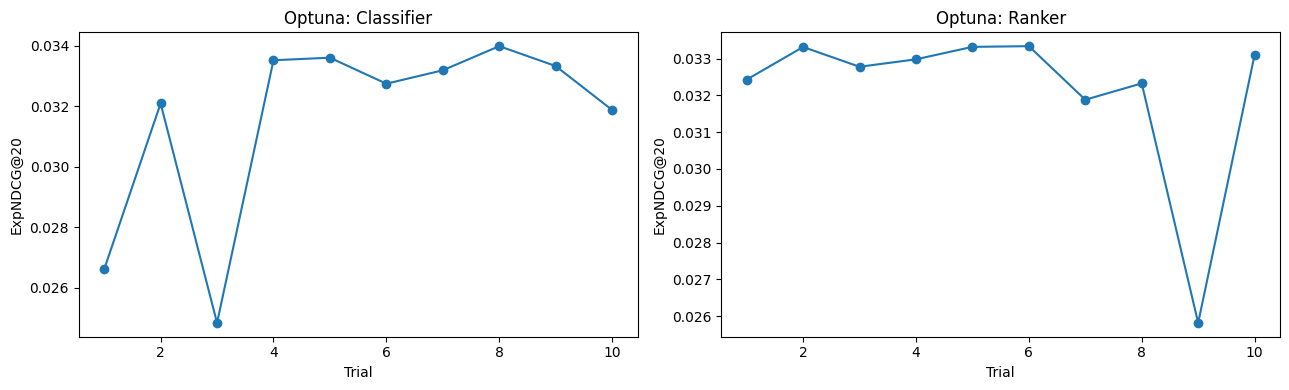

In [70]:
_, axes = plt.subplots(1, 2, figsize=(13, 4))

for study, name, ax in [
    (classifier_study, "Classifier", axes[0]),
    (ranker_study, "Ranker", axes[1]),
]:
    vals = [t.value for t in study.trials if t.value is not None]
    ax.plot(range(1, len(vals) + 1), vals, marker="o")
    ax.set(title=f"Optuna: {name}", xlabel="Trial", ylabel="ExpNDCG@20")

plt.tight_layout()
plt.show()

Визуализацию важностей вынесем в `plot_feature_importance`: получите важности признаков CatBoost, отсортируйте их, покажите top-15 и верните полную таблицу. Для `CatBoostRanker` при необходимости передайте training Pool.

Обратите внимание, какие признаки связаны с исторической активностью пользователя, какие описывают популярность товара, а какие — их сочетание. Высокая корреляция признаков может перераспределять важности между ними.

In [73]:
def plot_feature_importance(model, pool: Pool | None, title: str) -> pl.DataFrame:
    """Рисует top-15 важностей и возвращает полную таблицу признаков."""
    if pool is not None:
        importances = model.get_feature_importance(pool)
    else:
        importances = model.get_feature_importance()

    importances = np.asarray(importances, dtype=np.float64)

    #если столько же имен признаков сколько и самих важностей
    if "FEATURE_COLUMNS" in globals() and len(FEATURE_COLUMNS) == len(importances):
        feature_names = list(FEATURE_COLUMNS)
    elif pool is not None:
        names = pool.get_feature_names()
        feature_names = names if names and names[0] != "" else [f"f{i}" for i in range(len(importances))]
    else:
        feature_names = [f"f{i}" for i in range(len(importances))]

    table = (
        pl.DataFrame({"feature": feature_names, "importance": importances})
        .sort("importance", descending=True)
    )

    top15 = table.head(15).sort("importance")
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(top15["feature"].to_list(), top15["importance"].to_list())
    ax.set_title(title)
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.show()

    return table


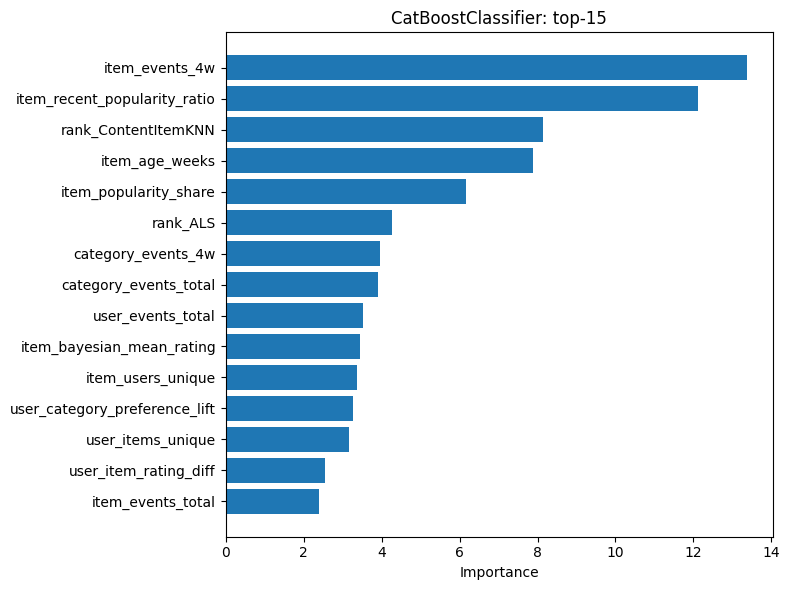

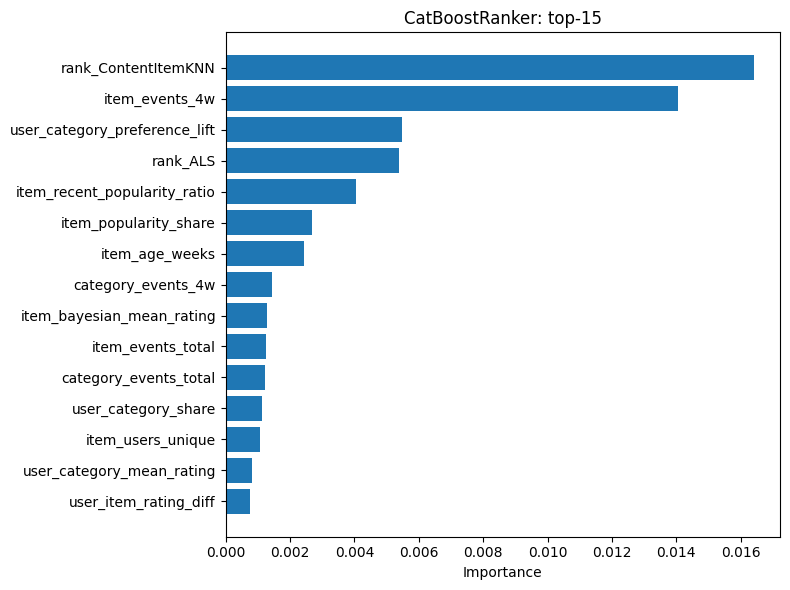

feature,importance
str,f64
"""item_events_4w""",13.370047
"""item_recent_popularity_ratio""",12.10627
"""rank_ContentItemKNN""",8.130396
"""item_age_weeks""",7.886219
"""item_popularity_share""",6.176514
"""rank_ALS""",4.261308
"""category_events_4w""",3.948388
"""category_events_total""",3.908295
"""user_events_total""",3.524229


feature,importance
str,f64
"""rank_ContentItemKNN""",0.016403
"""item_events_4w""",0.014039
"""user_category_preference_lift""",0.005491
"""rank_ALS""",0.005379
"""item_recent_popularity_ratio""",0.004051
"""item_popularity_share""",0.002674
"""item_age_weeks""",0.002421
"""category_events_4w""",0.001427
"""item_bayesian_mean_rating""",0.001272


In [74]:
classifier_importances = plot_feature_importance(
    classifier_model, None, "CatBoostClassifier: top-15"
)
ranker_importances = plot_feature_importance(
    ranker_model, train_group_pool, "CatBoostRanker: top-15"
)
display(classifier_importances.head(10))
display(ranker_importances.head(10))

## 12. Выбор ranking-модели по validation

Classifier и Ranker сравним на одном зафиксированном validation candidate pool. Состав кандидатов, признаки и функция внешней оценки одинаковы, поэтому различие метрик относится к выбранной постановке и её гиперпараметрам.

Победителя выберем по `ExpNDCG@20`, а при равенстве — по `MRR@20`. После этого тип модели и параметры фиксируются; `test` в выборе не участвует.

Pipeline,ExpNDCG@20,HitRate@20,MRR@20
str,f64,f64,f64
"""Union + CatBoostClassifier""",0.033982,0.099004,0.034221
"""Union + CatBoostRanker""",0.033336,0.101391,0.032129


Лучший ranking pipeline: Union + CatBoostClassifier


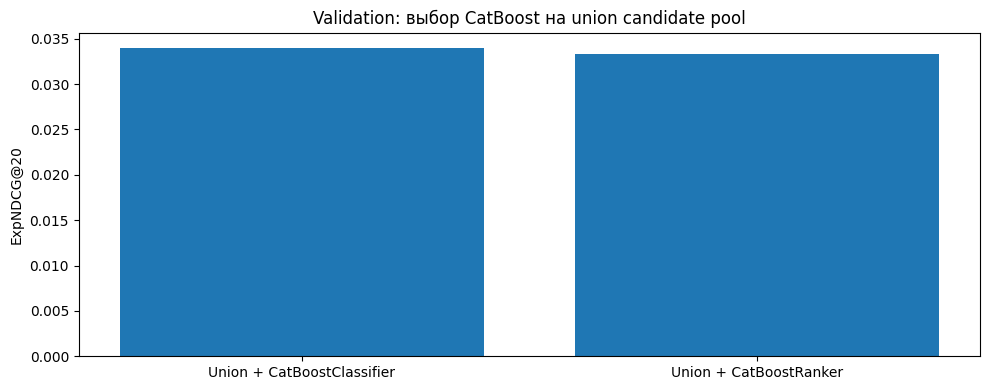

In [75]:
validation_reports = {}
ranking_models = {
    "Union + CatBoostClassifier": (classifier_model, "classifier"),
    "Union + CatBoostRanker": (ranker_model, "ranker"),
}

for name, (model, model_type) in ranking_models.items():
    ranked = rerank_candidates(
        model,
        val_candidate_features,
        model_type,
        FEATURE_COLUMNS,
        EVAL_K,
    )
    validation_reports[name] = evaluate_ranking(ranked, val_truth, EVAL_K)

validation_comparison = pl.DataFrame(
    [
        {"Pipeline": name, **report}
        for name, report in validation_reports.items()
    ]
).sort(f"ExpNDCG@{EVAL_K}", descending=True)
display(validation_comparison)

winner = sorted(
    ranking_models,
    key=lambda name: (
        -validation_reports[name][f"ExpNDCG@{EVAL_K}"],
        -validation_reports[name][f"MRR@{EVAL_K}"],
        name,
    ),
)[0]
best_ranker_type = ranking_models[winner][1]
best_ranker_params = (
    classifier_params if best_ranker_type == "classifier" else ranker_params
)

print("Лучший ranking pipeline:", winner)

plt.figure(figsize=(10, 4))
plt.bar(
    validation_comparison["Pipeline"],
    validation_comparison[f"ExpNDCG@{EVAL_K}"],
)
plt.ylabel(f"ExpNDCG@{EVAL_K}")
plt.title("Validation: выбор CatBoost на union candidate pool")
plt.tight_layout()
plt.show()

## 13. Финальный эксперимент на `test`

После фиксации конфигурации переобучим retrieval-модели и выбранный CatBoost на `train + validation`. Затем один раз оценим готовый пайплайн на `test`; события тестовых недель не используются ни для переобучения, ни для пересмотра параметров.

Сравнение построим так, чтобы разделить изменение порядка и изменение состава кандидатов. Пара `retrieval` / `retrieval + CatBoost` использует один candidate pool и показывает эффект reranking. `Union + CatBoost` работает с объединённым пулом, поэтому его результат дополнительно зависит от кандидатов, найденных другими источниками.

В итоговую таблицу войдут исходные TopPopular, ContentItemKNN и ALS, каждый одиночный источник после CatBoost и CatBoost на объединённом пуле кандидатов.

Тип модели и гиперпараметры уже зафиксированы на validation. Теперь добавляем
информативные validation candidate groups в ranking train и переобучаем выбранный
CatBoost.

In [76]:
train_val_rank = pl.concat(
    [train_rank, val_rank],
    how="vertical_relaxed",
)
train_val_events = pl.concat(
    [train_events, val_events],
    how="vertical_relaxed",
)

if best_ranker_type == "classifier":
    final_ranker = make_classifier(best_ranker_params)

    final_ranker.fit(
        train_val_rank.select(FEATURE_COLUMNS).to_numpy().astype(np.float32),
        train_val_rank["binary_target"].to_numpy(),
    )
else:
    final_ranker = make_ranker(best_ranker_params)

    final_ranker.fit(
        prepare_ranking_pool(
            filter_informative_ranking_groups(train_val_rank),
            FEATURE_COLUMNS,
        )
    )

Обучим три retrieval-модели на `train + validation` и зафиксируем их на всём test-периоде. Для пользователей тестовых недель генерируем по 100 рекомендаций с исключением уже просмотренных на начало недели; point-in-time признаки также учитывают только завершённые недели. Такой порядок согласован с подготовкой validation-кандидатов.

In [77]:
final_retrievers = fit_retrievers(train_val_events)

test_sessions = test_truth.select("session_id", "week_start", "user_id").unique()
test_lists = generate_candidate_lists(
    final_retrievers,
    test_sessions,
    interactions,
    RETRIEVAL_K,
)

test_union = merge_candidates(test_lists)
unique_test_features = join_feature_snapshot(test_union, DATAMART_DIR)

  0%|          | 0/15 [00:00<?, ?it/s]

Чтобы оценить собственное качество каждого кандидатогенератора, оставим его исходные первые 20 рекомендаций.

In [78]:
result_rows = []

for name, recs in test_lists.items():
    report = evaluate_ranking(
        recs.filter(pl.col("position") <= EVAL_K),
        test_truth,
        EVAL_K,
    )
    result_rows.append({"Pipeline": name, **report})

Теперь для каждого генератора сохраняем то же множество top-100 товаров, но сортируем их с помощью выбранного CatBoost. Это сравнение измеряет эффект именно изменения порядка, а не расширения пула.

In [79]:
for name in test_lists:
    source_candidates = unique_test_features.filter(pl.col(f"from_{name}") == 1)

    new_order = rerank_candidates(
        final_ranker,
        source_candidates,
        best_ranker_type,
        FEATURE_COLUMNS,
        EVAL_K,
    )

    report = evaluate_ranking(new_order, test_truth, EVAL_K)
    result_rows.append({"Pipeline": f"{name} + CatBoost", **report})

В последнем эксперименте берём кандидатов **от всех трёх моделей**. Один товар может встретиться в нескольких списках, поэтому применяем следующий порядок:

$$\text{TopPopular}\cup\text{ContentItemKNN}\cup\text{ALS}\;\to\;\text{unique}(session,item)\;\to\;\text{features}\;\to\;\text{CatBoost}\;\to\;\text{top-20}.$$

Дедупликация происходит до скоринга, не после. `Union + CatBoost` отличается от одиночных источников и составом кандидатов, поэтому его выигрыш нельзя приписывать только ранкеру.

In [80]:
union_ranked = rerank_candidates(
    final_ranker,
    unique_test_features,
    best_ranker_type,
    FEATURE_COLUMNS,
    EVAL_K,
)
result_rows.append(
    {
        "Pipeline": "Union + CatBoost",
        **evaluate_ranking(union_ranked, test_truth, EVAL_K),
    }
)

TEST_METRICS = pl.DataFrame(result_rows).sort(
    f"ExpNDCG@{EVAL_K}",
    descending=True,
)
display(TEST_METRICS)

Pipeline,ExpNDCG@20,HitRate@20,MRR@20
str,f64,f64,f64
"""Union + CatBoost""",0.036703,0.120055,0.034777
"""ALS + CatBoost""",0.031663,0.098254,0.031282
"""ContentItemKNN + CatBoost""",0.025963,0.084838,0.029351
"""ALS""",0.024309,0.074973,0.023128
"""ContentItemKNN""",0.014617,0.056526,0.01533
"""TopPopular + CatBoost""",0.010725,0.042518,0.012721
"""TopPopular""",0.006692,0.030384,0.007679


Соберём таблицу `ExpNDCG@20`, `HitRate@20`, `MRR@20` и сравним исходные и переупорядоченные выдачи. Для каждого отдельного источника полезно рассчитать **разницу** `ExpNDCG` после и до CatBoost.

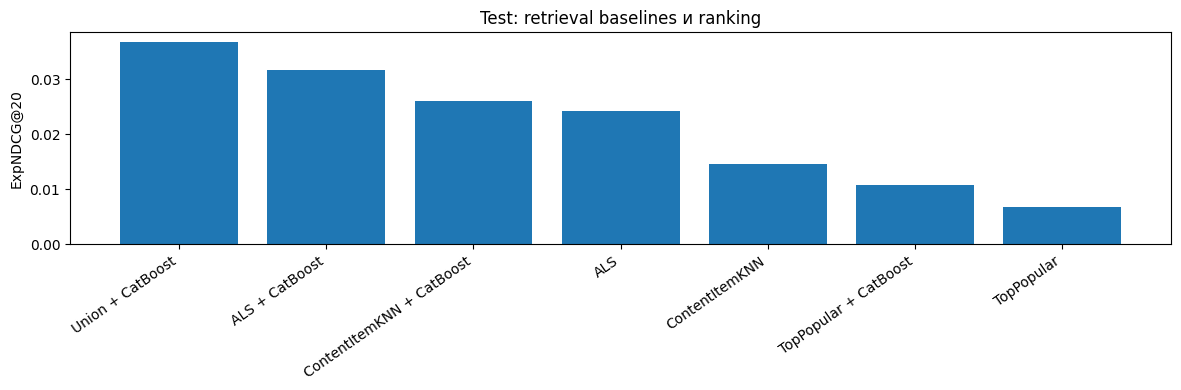

TopPopular: delta ExpNDCG@20 = +0.00403
ContentItemKNN: delta ExpNDCG@20 = +0.01135
ALS: delta ExpNDCG@20 = +0.00735
Union + CatBoost vs best retrieval: +0.01239


In [81]:
labels = TEST_METRICS["Pipeline"].to_list()
values = TEST_METRICS[f"ExpNDCG@{EVAL_K}"].to_list()

plt.figure(figsize=(12, 4))
plt.bar(range(len(labels)), values)
plt.xticks(range(len(labels)), labels, rotation=35, ha="right")
plt.ylabel(f"ExpNDCG@{EVAL_K}")
plt.title("Test: retrieval baselines и ranking")
plt.tight_layout()
plt.show()

for name in ("TopPopular", "ContentItemKNN", "ALS"):
    base = TEST_METRICS.filter(pl.col("Pipeline") == name)[f"ExpNDCG@{EVAL_K}"][0]
    reranked = TEST_METRICS.filter(pl.col("Pipeline") == f"{name} + CatBoost")[
        f"ExpNDCG@{EVAL_K}"
    ][0]

    print(f"{name}: delta ExpNDCG@{EVAL_K} = {reranked - base:+.5f}")

best_retrieval_test = max(
    ("TopPopular", "ContentItemKNN", "ALS"),
    key=lambda name: TEST_METRICS.filter(pl.col("Pipeline") == name)[
        f"ExpNDCG@{EVAL_K}"
    ][0],
)

best_retrieval_value = TEST_METRICS.filter(pl.col("Pipeline") == best_retrieval_test)[
    f"ExpNDCG@{EVAL_K}"
][0]
union_value = TEST_METRICS.filter(pl.col("Pipeline") == "Union + CatBoost")[
    f"ExpNDCG@{EVAL_K}"
][0]

print(
    "Union + CatBoost vs best retrieval:",
    f"{union_value - best_retrieval_value:+.5f}",
)

## 14. Выводы по домашнему заданию (1p)

В выводах нужно интерпретировать полученные таблицы. Расскажите о том, что удалось пронаблюдать, а также ответьте на следующие вопросы:

1. Почему candidate-based hard negatives лучше согласованы с inference, чем
   случайные популярные товары?
2. Какие retrieval-признаки вошли в top feature importance?
3. Чем отличаются classifier и ranker по target и loss?
4. Какая модель победила на validation?
5. Улучшил ли CatBoost каждый отдельный retrieval source на test?
6. Почему `Union + CatBoost` сравнивается с лучшим одиночным retrieval отдельно?
7. Какие группы исключаются из ranking train и почему ranking не может исправить
   отсутствие positive item в candidate pool?
8. Как point-in-time snapshots предотвращают temporal leakage и согласуется с продовым пайплайном?

## 1) candidate-based hard negatives показывают такой пул, с которым модель столкнулась бы при ранжировании в реальной ситуации. hard negatives из retrieval-выдачи близки по смыслу к положительным примерам (например, это товары из тех же категорий или с похожими эмбеддингами), поэтому CatBoost учится на границе принятия решений, как при реальном выборе top-20. Это дает более реальную калибровку scores и увеличивает ExpNDCG@20 (по нашим результатам видно, что есть прирост к базовым retrieval-моделям и к лучшим из них при объединении кандидатов - см. последнюю визуализацию).

## 2) rank_ContentItemKNN и rank_ALS вошли в топ, но они на разных местах - У CatBoostClassifier rank_ContentItemKNN на 3 месте, а rank_ALS на 6 месте.
## У CatBoostRanker rank_ContentItemKNN занимает 1 место, а rank_ALS - 4 место.

##Флаги источников (from_*) и кол-во источников (source_count) в топ-15 не попали,модели используют именно позицию в ранжировании от ретриверов в качестве главного аргумента. ContentItemKNN для обеих моделей оказался важнее ALS.



## 3) classifier решает задачу бинарной классификации (1 или 0), а ranker решает групповую задачу ранжирования (target = relevance от 1 до 5 например). Поэтому и важности признаков у них разные: для classifier важна популярность товара (item_events_4w, item_recent_popularity_ratio), потому что это хорошие предикторы самого факта взаимодействия, а для ranker важна позиция в retrieval-выдаче (rank_ContentItemKNN - на первом месте) и кросс-признаки, например user_category_preference_lift, т.к. они помогают различать товары относительно друг друга внутри одной группы

## 4) победил CatBoostClassifier. На графике optuna видим, что его лучший ExpNDCG@20 на validation составил примерно 0.0338 (trial 8), а у CatBoostRanker максимум был около 0.0333 (trial 2). Разница небольшая, но classifier оказался чуть впереди.

## 5) видим из последней нашей визуализации, что CatBoost улучшил и TopPopular (+0.004), и ALS (+0.007), и ContentItemKNN (+0.011).

## 6) Union + CatBoost сравнивается с лучшим одиночным retrieval отдельно, чтобы ответить на главный вопрос задания: дает ли объединение нескольких источников кандидатов лучший результат? Если бы Union + CatBoost улучшал только у слабых ретриверов, но не давал преимуществ лучшему из них, это означало бы, что объединение источников бесполезно (значит надо просто использовать сильный ретривер ALS). Но мы видим, что Union + CatBoost = 0.0367 против ALS, например (0.0243), разница +0.0124 доказывает, что объединение превосходит даже лучший одиночный retrieval.

## 7) Из ranking train исключаются сессии, где менее двух кандидатов/все кандидаты имеют одинаковый уровень релевантности (например, все нули или все пятеки), потому что в таких группах yetirank не может построить градиент - сравнивать внутри группы нечего, там все одинаковое.
##Ранжирование не может исправить отсутствие позитивного товара в пуле кандидатов, потому что ranker просто расставляет по местам уже имеющиеся варианты, не добавляя новые (поэтому этап retrieval так важен - его полнота (recall то есть) задает потолок качества, а ranking не может выдать что-то выше него)

## 8) Point-in-time snapshots предотвращают temporal leakage тем, что для каждой недели признаки строятся по событиям из прошлого, исключая любые данные из целевой недели и будущего. Сохранение этих срезов гарантирует, что при сборке датасета мы используем именно то состояние данных, которое было известно на начало недели.
##То есть события новой недели служат для оценки и не могут повлиять на уже выведенный output - так модель учится на той же информации, что будет доступна в момент инференса.

# Основной вывод по нашим визуализациям и таблицам состоит в том, что объединение нескольких retrieval-источников с последующим ранжированием дает лучший результат, превосходя лучший одиночный retrieval.
#CatBoost улучшает каждый отдельный источник, а feature importance наглядно показывает, почему модели ведут себя по-разному - classifier опирается в основном на популярность товара, а ranker сильнее доверяет позиции в retrieval-выдаче. Значит, в реальных задачах пайплайн с объединением кандидатов и использованием CatBoost будет наиболее эффективным решением!